# Earth as an Exoplanet: From Habitable to Biodiverse
**Jake Lowe, Andrew Klingberg, B.B. Cael, & Kelsey Bisson (2026)** </BR>
Last updated: October 28, 2026

# 1. Set up

In [ ]:
%pip install -r requirements.txt

In [1]:
import earthaccess
import os
import pickle
import pandas as pd
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.append("..")

# PACE modules
from modules.pace_utils import * # Contains all processing/plotting functions for PACE data
from modules.ref_dict import * # Contains all reference dictionaries

# Earthaccess login
auth = earthaccess.login(persist=True) # Requires creation of an Earthdata account
print("Earthdata authentication successful.")

# Data directory
data_dir = "C:/Users/jakel/Desktop/Projects/PACE_pub/data"

Earthdata authentication successful.


In [2]:
# import warnings
# warnings.filterwarnings('ignore', category=FutureWarning)

# 2. NASA PACE OCI Processing (Stream/Cache/Plot)
Adapted from work by Skye Caplan (NASA, SSAI), Sean Foley (NASA, MSU), Meng Gao (NASA, SSAI), & Ian Carroll (NASA, UMBC) </BR>
*Modules utilized: pace_utils, ref_dict* </BR>
## 2.1 Surface Reflectance
OCI L2 Surface Reflectance V3.1 Near-Real-Time (SFREFL NRT); </BR>
Provides the ability to mask cloud pixels for spectral averages, ~5 km pixels </BR>
*Note: In the future, may have to change granule search to SFREFL (remove NRT)*

In [3]:
#NOTE: Uncomment to stream/cache Earthdata granules, check "pace_dict" module to (de)select specific biomes 
# processed_data = {}

# for target in oci_granules:
#     result = extract_spectra(
#         short_name="PACE_OCI_L2_SFREFL", granule_dict=target, cache_dir=os.path.join(data_dir, "sfrefl_cache") #NOTE: check SFREFL vs. SFREFL_NRT here
#     )
#     if result:
#         processed_data[target["name"]] = result

Plotting: Rainforest (poi) | spatial pixels: 44
Plotting: Amazon (granule) | spatial pixels: 200606
Grasslands (poi): no contributing spatial pixels
Plotting: Mongolia (granule) | spatial pixels: 200112
Plotting: Everglades (poi) | spatial pixels: 16
Plotting: US_southeast (granule) | spatial pixels: 198908
Plotting: Okefenokee (poi) | spatial pixels: 22
Plotting: Wasatch Forest (poi) | spatial pixels: 17
Plotting: US_west (granule) | spatial pixels: 196149


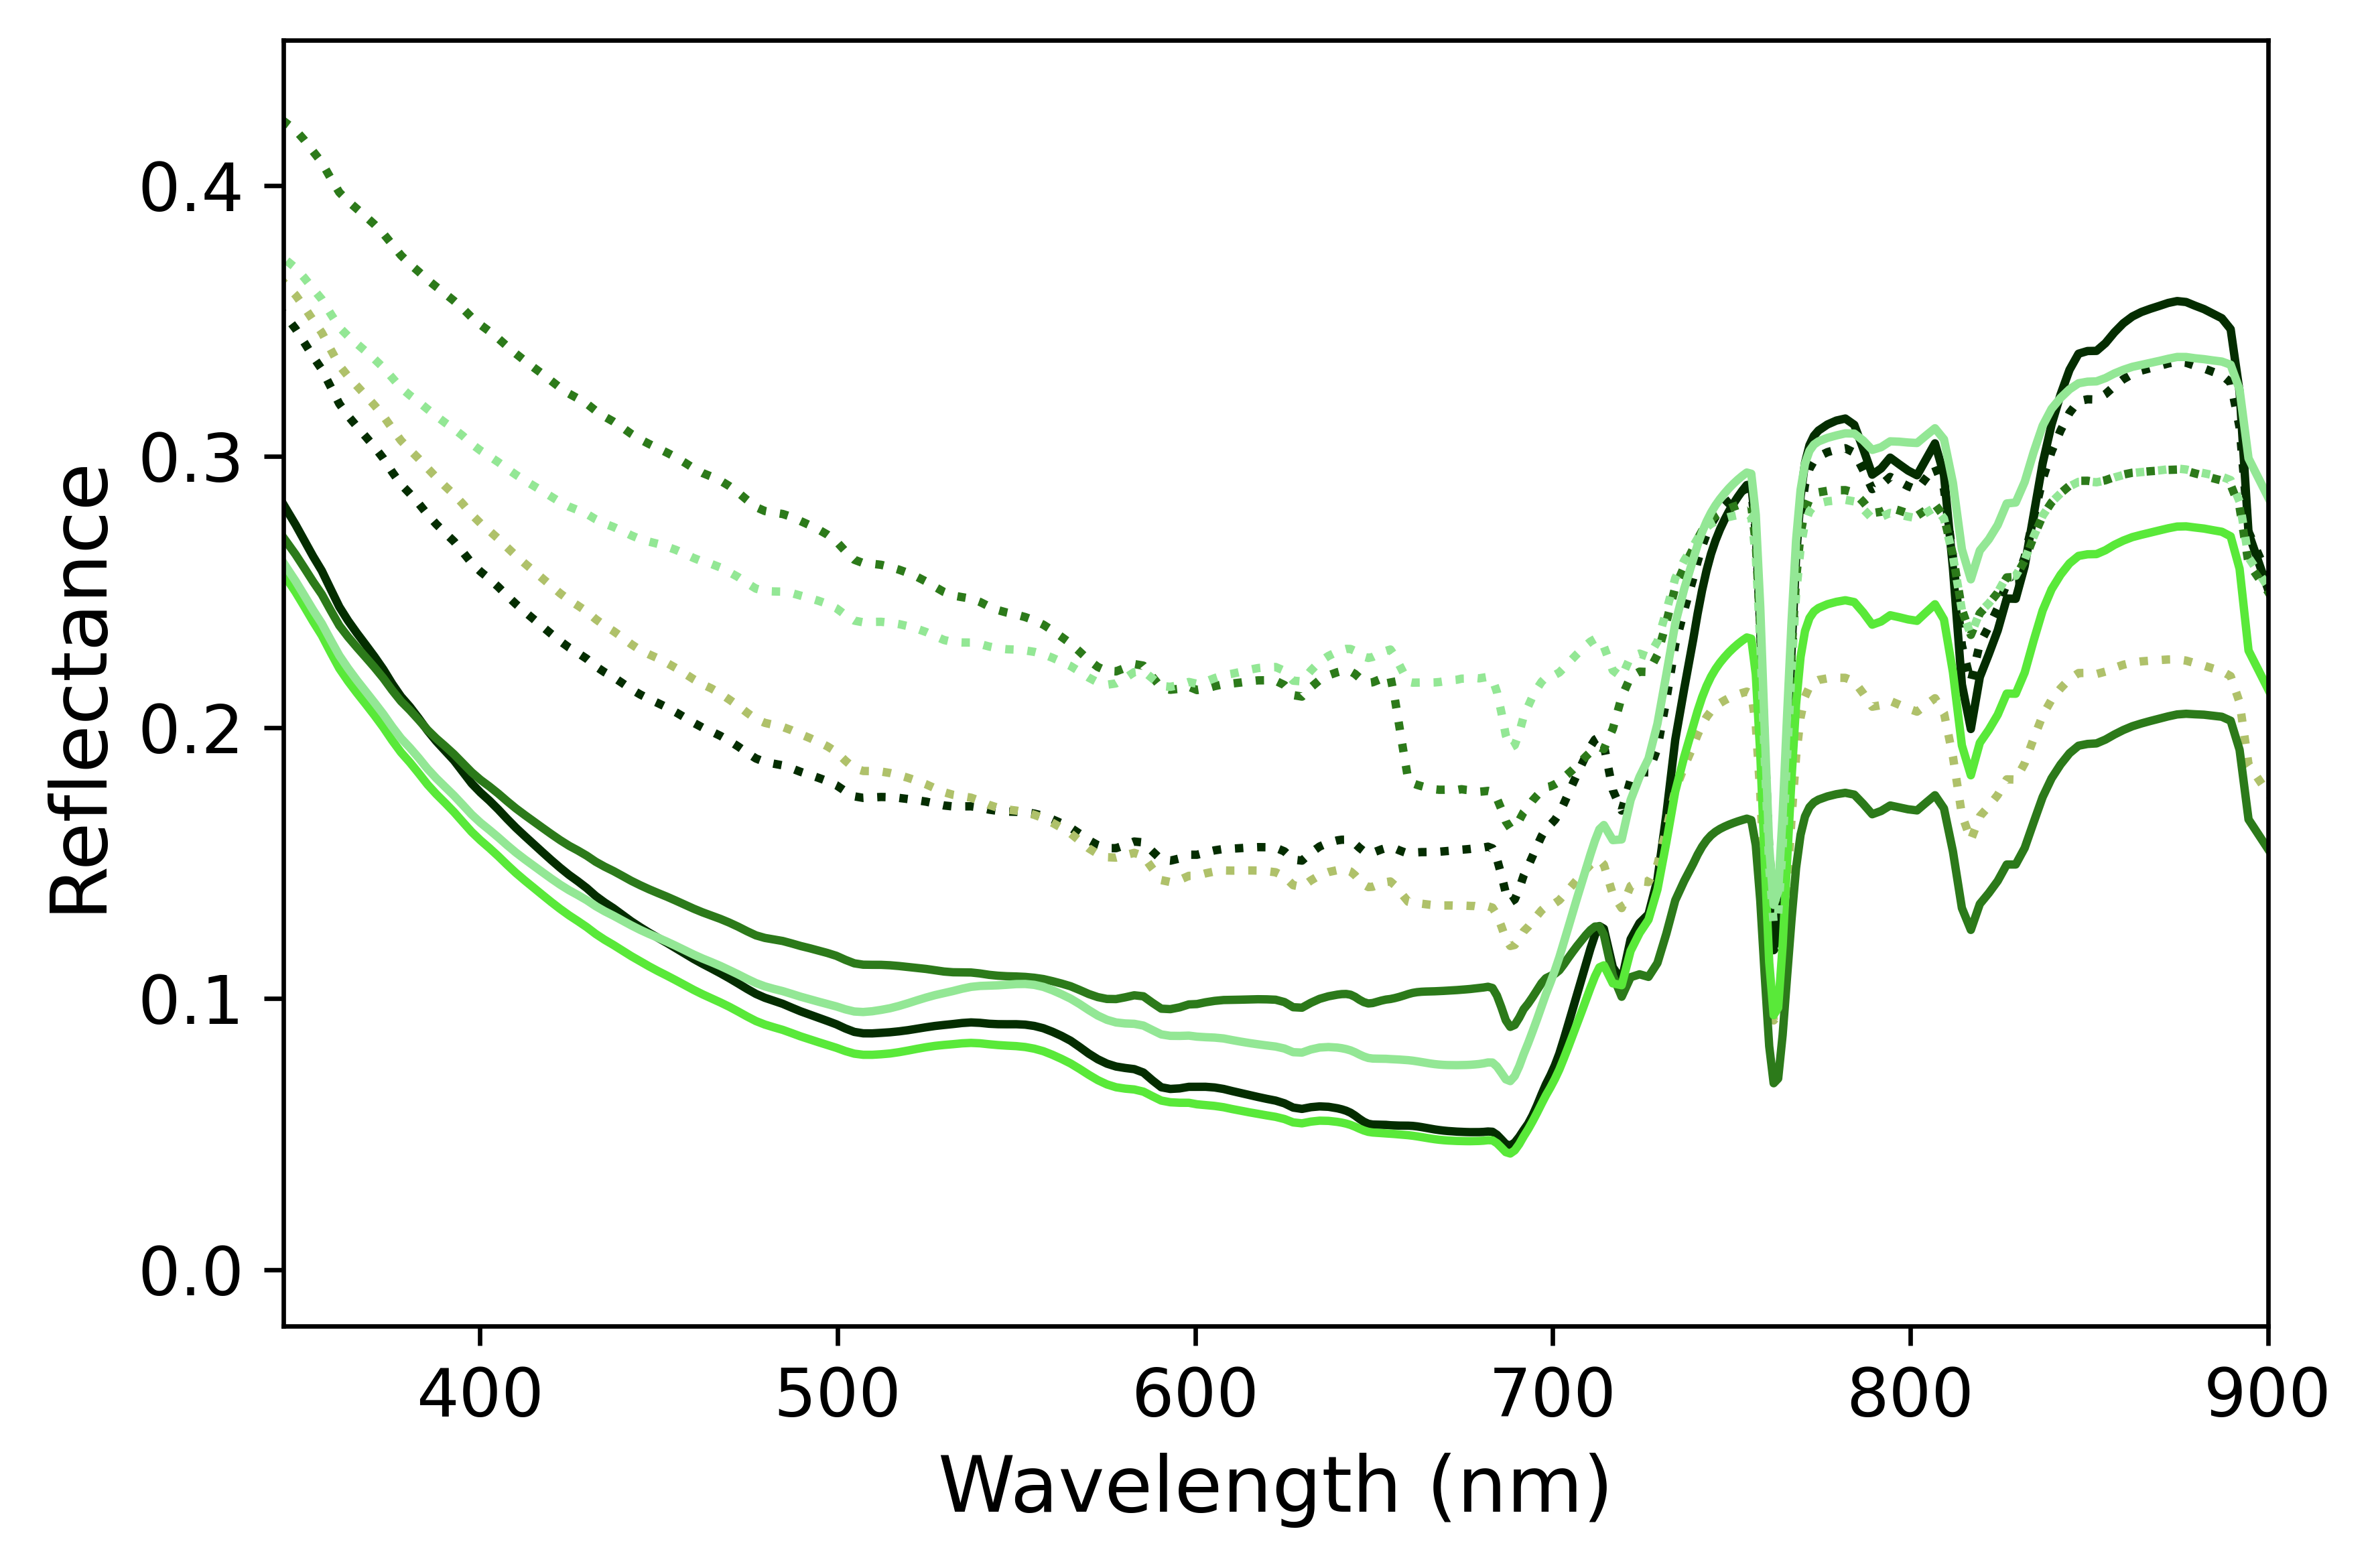

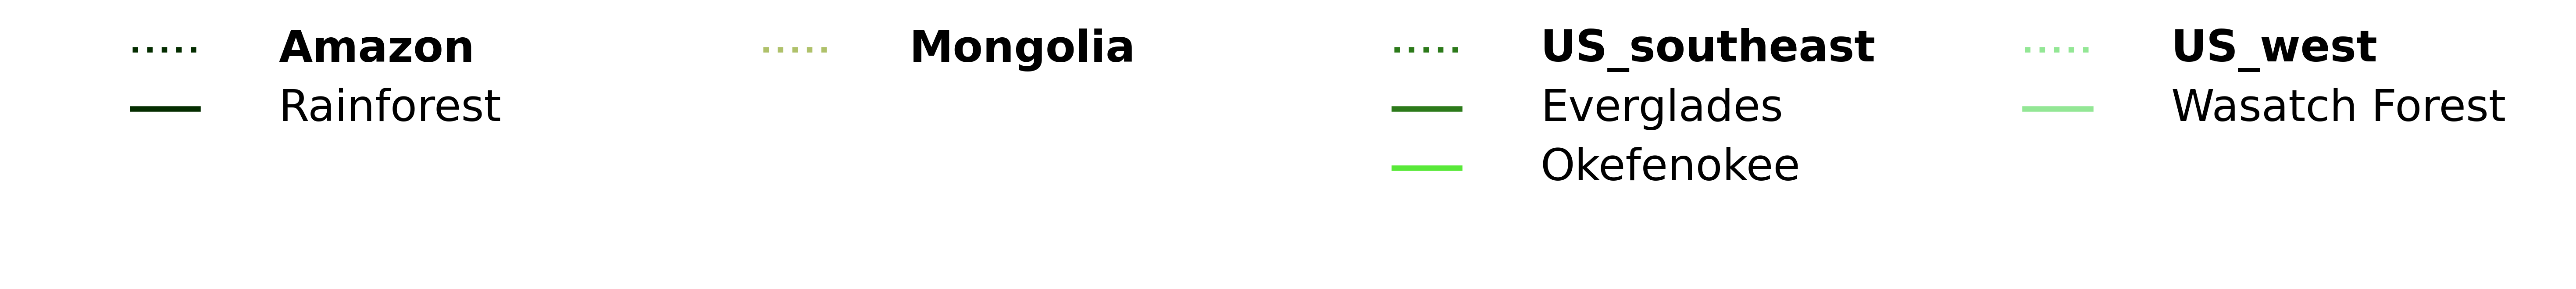

(<Figure size 3600x2400 with 1 Axes>, <Figure size 6000x720 with 1 Axes>, {})

In [4]:
sfrefl_cache = os.path.join(data_dir, "toa_cache") # toggle between sfrefl and toa for different figs
sfrefl_files, total_profiles = get_cached_files(sfrefl_cache, biomes)

plot_biome_spectra(
    valid_files=sfrefl_files,
    cache_dir=sfrefl_cache,
    biomes=biomes,
    target_sub_biomes = [
    # Abiotic:
        #"Open Ocean", "Craters of the Moon", "Salt Flats", "Atacama", "Sahara",
        #"CA Open Ocean", "CA Upwelling", "Pyramid Lake (Summer)", "Zuni Lava Fields", "Roger's Dry Lake", "Antarctica",
    # Vegetation:
        "Rainforest", "Okefenokee", "Grasslands", "Everglades", "Wasatch Forest",
    # Microbial:
        #"Coccolithophores", "Algal Bloom", "Coral Reef", "Stromatolites", 
        #"GSL North Arm", "GSL South Arm", #"Pyramid Lake (Fall)", 
    ],
    spatial_level=["poi", "granule"], #"granule", "bbox", "poi"
    xlim=(345,900) #380,750
)

### Plot Map

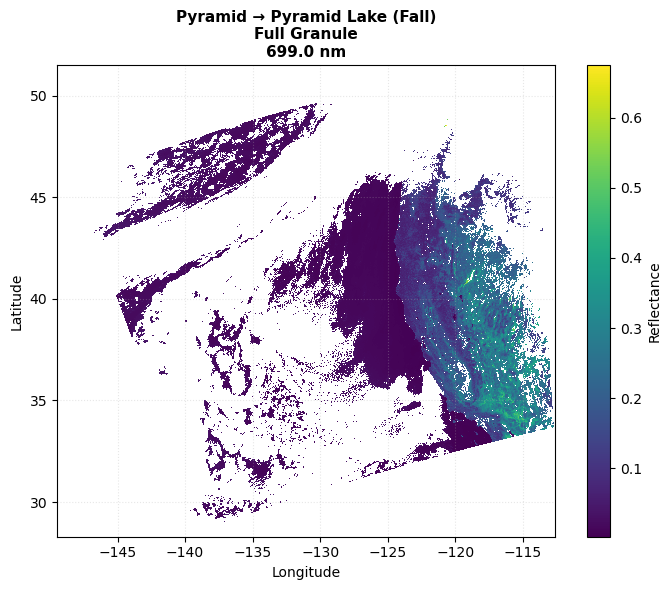

In [5]:
plot_biome_maps(
    valid_files=sfrefl_files,
    cache_dir=sfrefl_cache,
    biomes=biomes,
    target_wl=700,
    target_sub_biome="Pyramid Lake (Fall)",
    bbox_override=None, #[-120, 39.5, -119, 40.5]
)

## 2.2 TOA Reflectance
OCI L1C V3 top of atmosphere reflectance, calculated from radiance, ~5.2 km pixels </BR>
L1C data are co-mapped to the same grid, accounting for differences in spatial geometry / viewing angles between instruments

In [6]:
# #NOTE: Uncomment to stream/cache Earthdata granules, check "pace_dict" module to (de)select specific biomes 
# processed_data = {}

# for target in oci_granules:
#     result = extract_spectra(
#         short_name="PACE_OCI_L1C_SCI", granule_dict=target, cache_dir=os.path.join(data_dir, "toa_cache")
#     )
#     if result:
#         processed_data[target["name"]] = result

Plotting: Coral Reef (poi) | spatial pixels: 7
Plotting: Stromatolites (poi) | spatial pixels: 17
Plotting: Rainforest (poi) | spatial pixels: 44
Plotting: Atacama (poi) | spatial pixels: 17
Plotting: Coccolithophores (poi) | spatial pixels: 28
Plotting: Algal Bloom (poi) | spatial pixels: 7
Plotting: Open Ocean (poi) | spatial pixels: 678
Pyramid Lake (Fall) (poi): no contributing spatial pixels
Plotting: Sahara (poi) | spatial pixels: 25
Plotting: Okefenokee (poi) | spatial pixels: 22
Plotting: Salt Flats (poi) | spatial pixels: 18
Plotting: Craters of the Moon (poi) | spatial pixels: 4


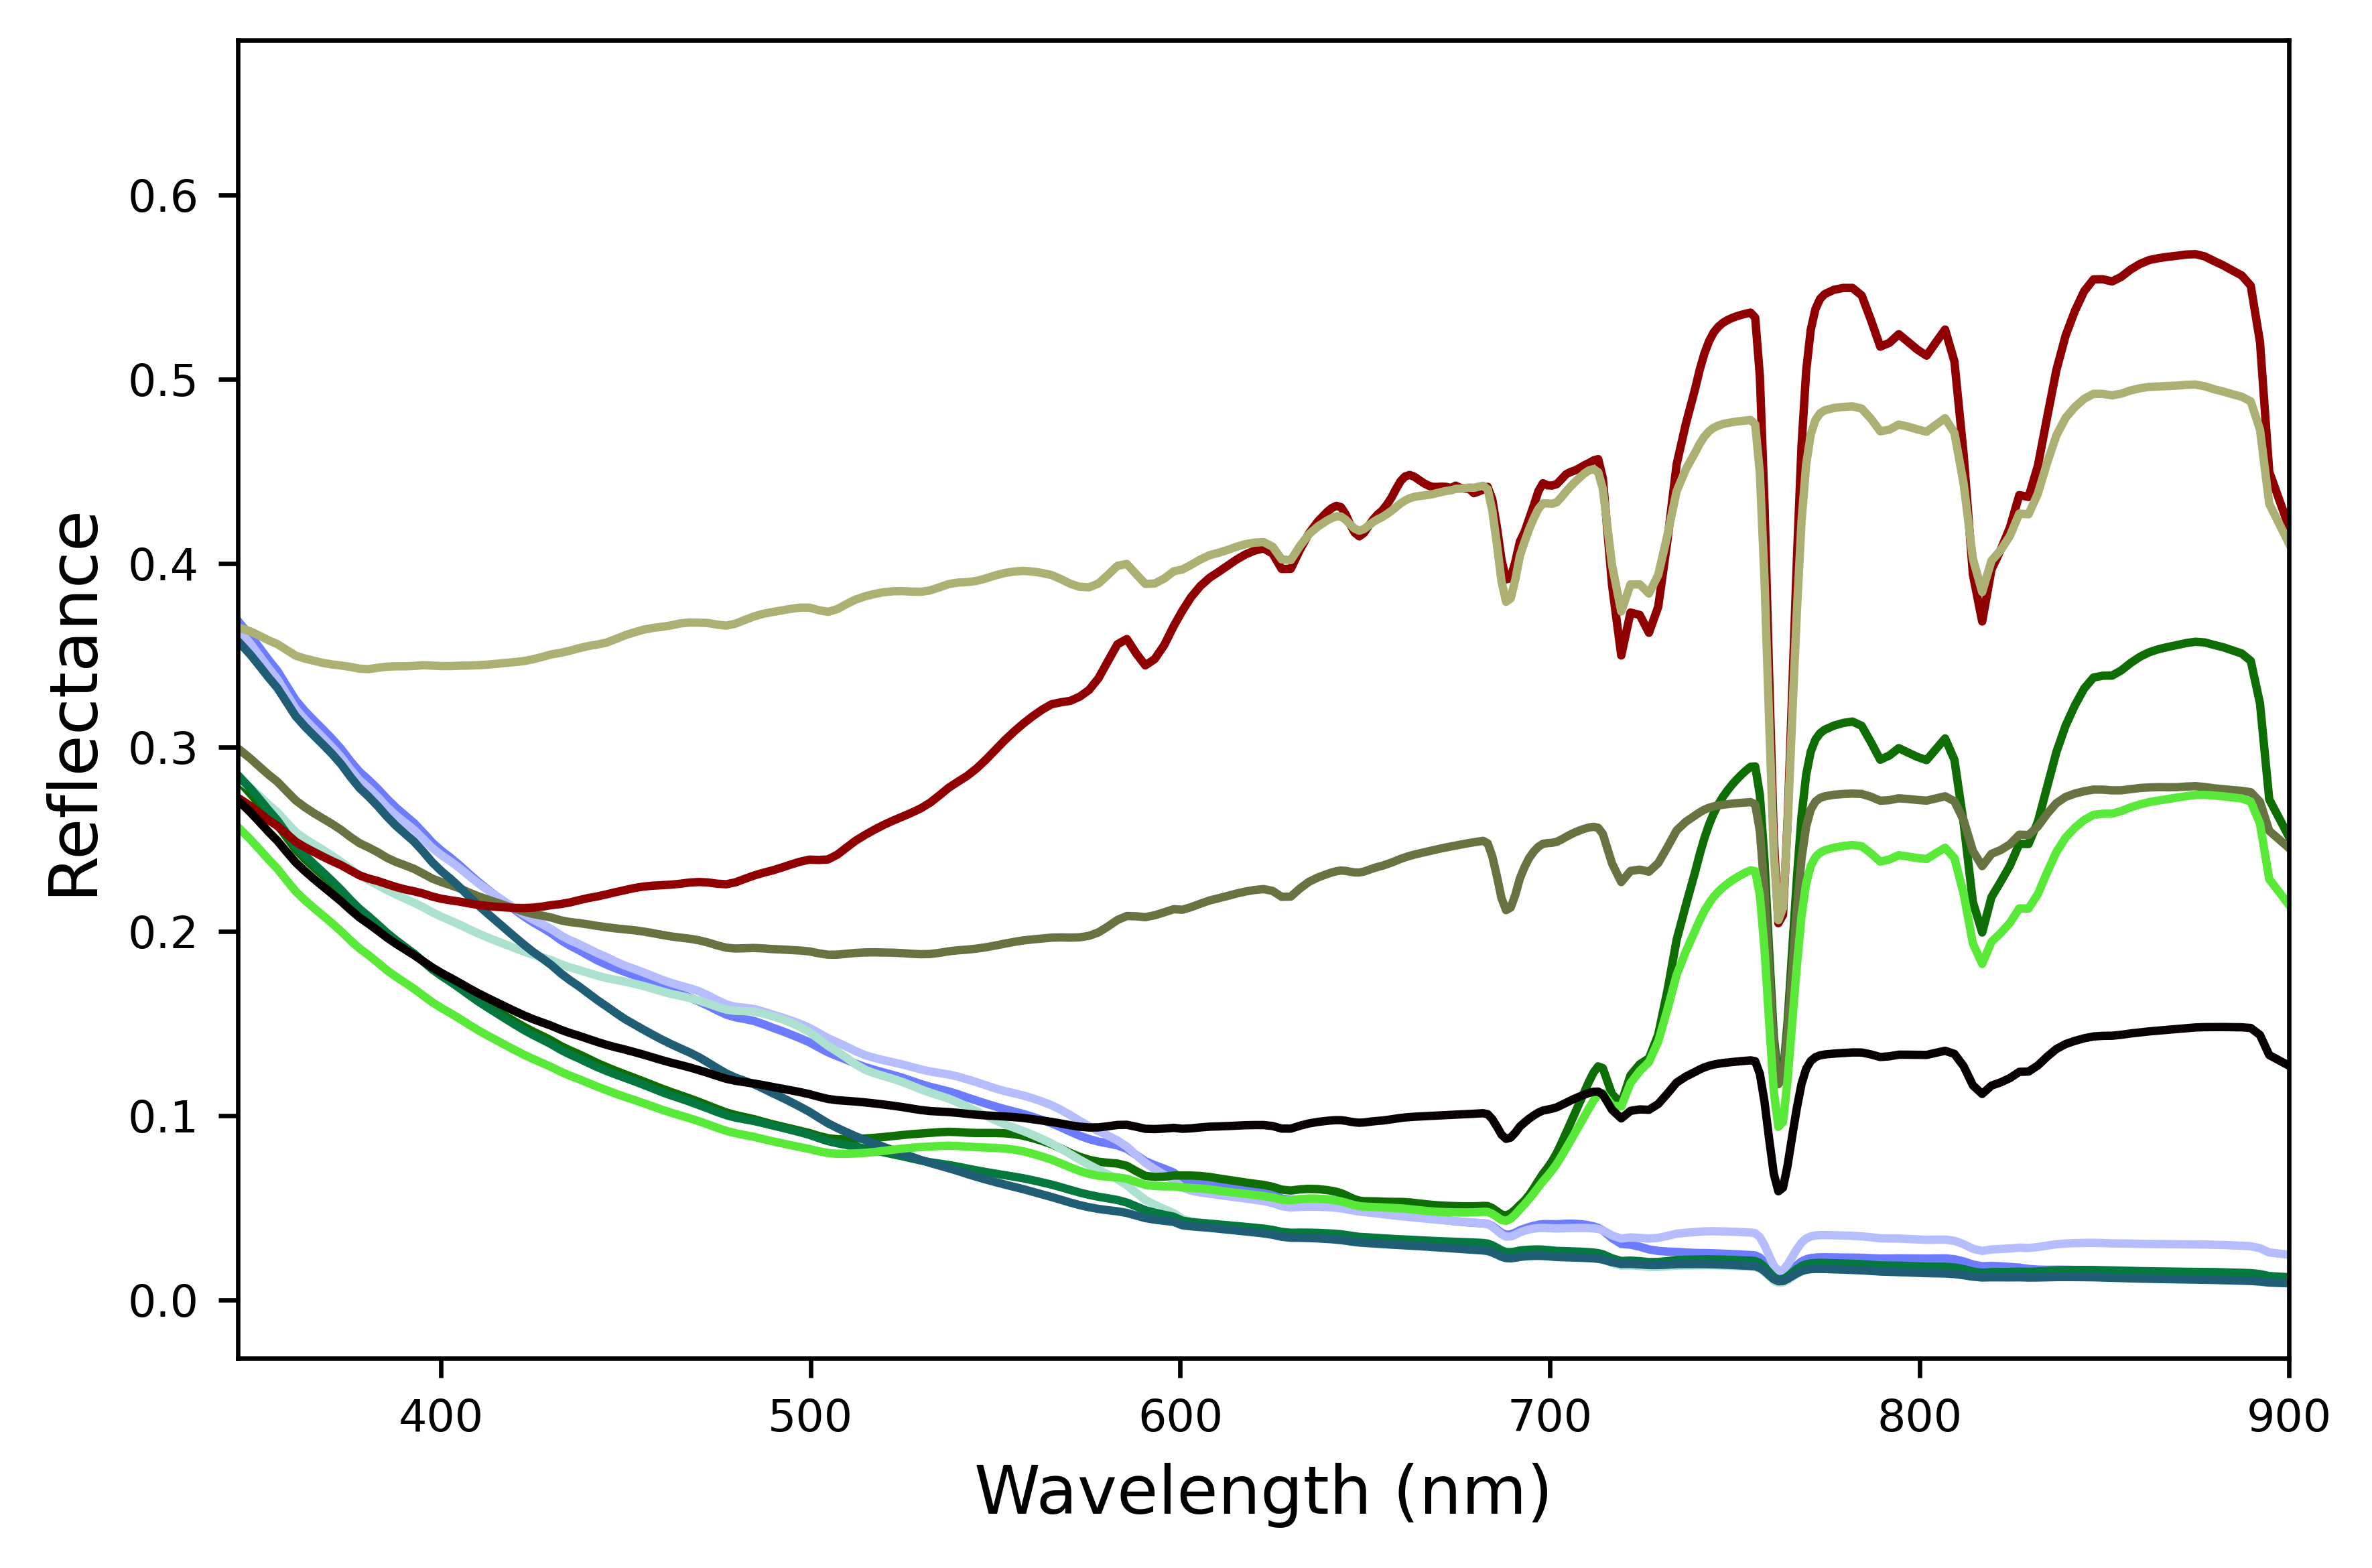



(<Figure size 3600x2400 with 1 Axes>, <Figure size 13500x720 with 1 Axes>, {})

In [7]:
toa_cache = os.path.join(data_dir, "toa_cache")
toa_files, total_profiles = get_cached_files(toa_cache, biomes)

plot_biome_spectra(
    valid_files=toa_files,
    cache_dir=toa_cache,
    biomes=biomes,
        target_sub_biomes=[
        # Vegetation:
            "Rainforest", "Okefenokee", 
            #"Grasslands", "Everglades", 
        # Microbial:
            "Coccolithophores", "Algal Bloom", "Pyramid Lake (Fall)", "Coral Reef", "Stromatolites", 
            #"GSL North Arm", "GSL South Arm",
        # Abiotic:
            "Open Ocean", "Craters of the Moon", "Salt Flats", "Atacama", "Sahara",  
            #"CA Open Ocean", "CA Upwelling", "Pyramid Lake (Summer)", "Zuni Lava Fields", "Roger's Dry Lake", "Antarctica",
        ], 
    spatial_level=["poi"], #"granule", "bbox", "poi"
    xlim=(345,900)
)

# 3. Galileo Comparison
Galileo NIMS data was rewritten directly from Sagan *et al.* (1993) using https://automeris.io (WebPlotDigitizer, V5.2; Ankit Rohatgi) </BR>
*Modules utilized: galileo_utils, ref_dict* </BR>

In [8]:
from modules.galileo_utils import * # Contains functions to stream/cache/plot OCI radiance and Galileo NIMS data
galileo_dir = os.path.join(data_dir, "galileo")

In [9]:
# # Retrieve radiance values for South Pacific open ocean pixels:
# processed_data = {}

# for target in galileo_granules:
#     result = extract_radiance_spectra(
#         short_name="PACE_OCI_L1C_SCI", granule_dict=target, cache_dir=galileo_dir
#     )
#     if result:
#         processed_data[target["name"]] = result

## 3.1 Radiance 
PACE OCI (UV-SWIR) vs. Galileo NIMS (NIR-MIR) </BR>
Panels separated/reprinted as in Sagan *et al.* (1993) to show detail in regions of interest

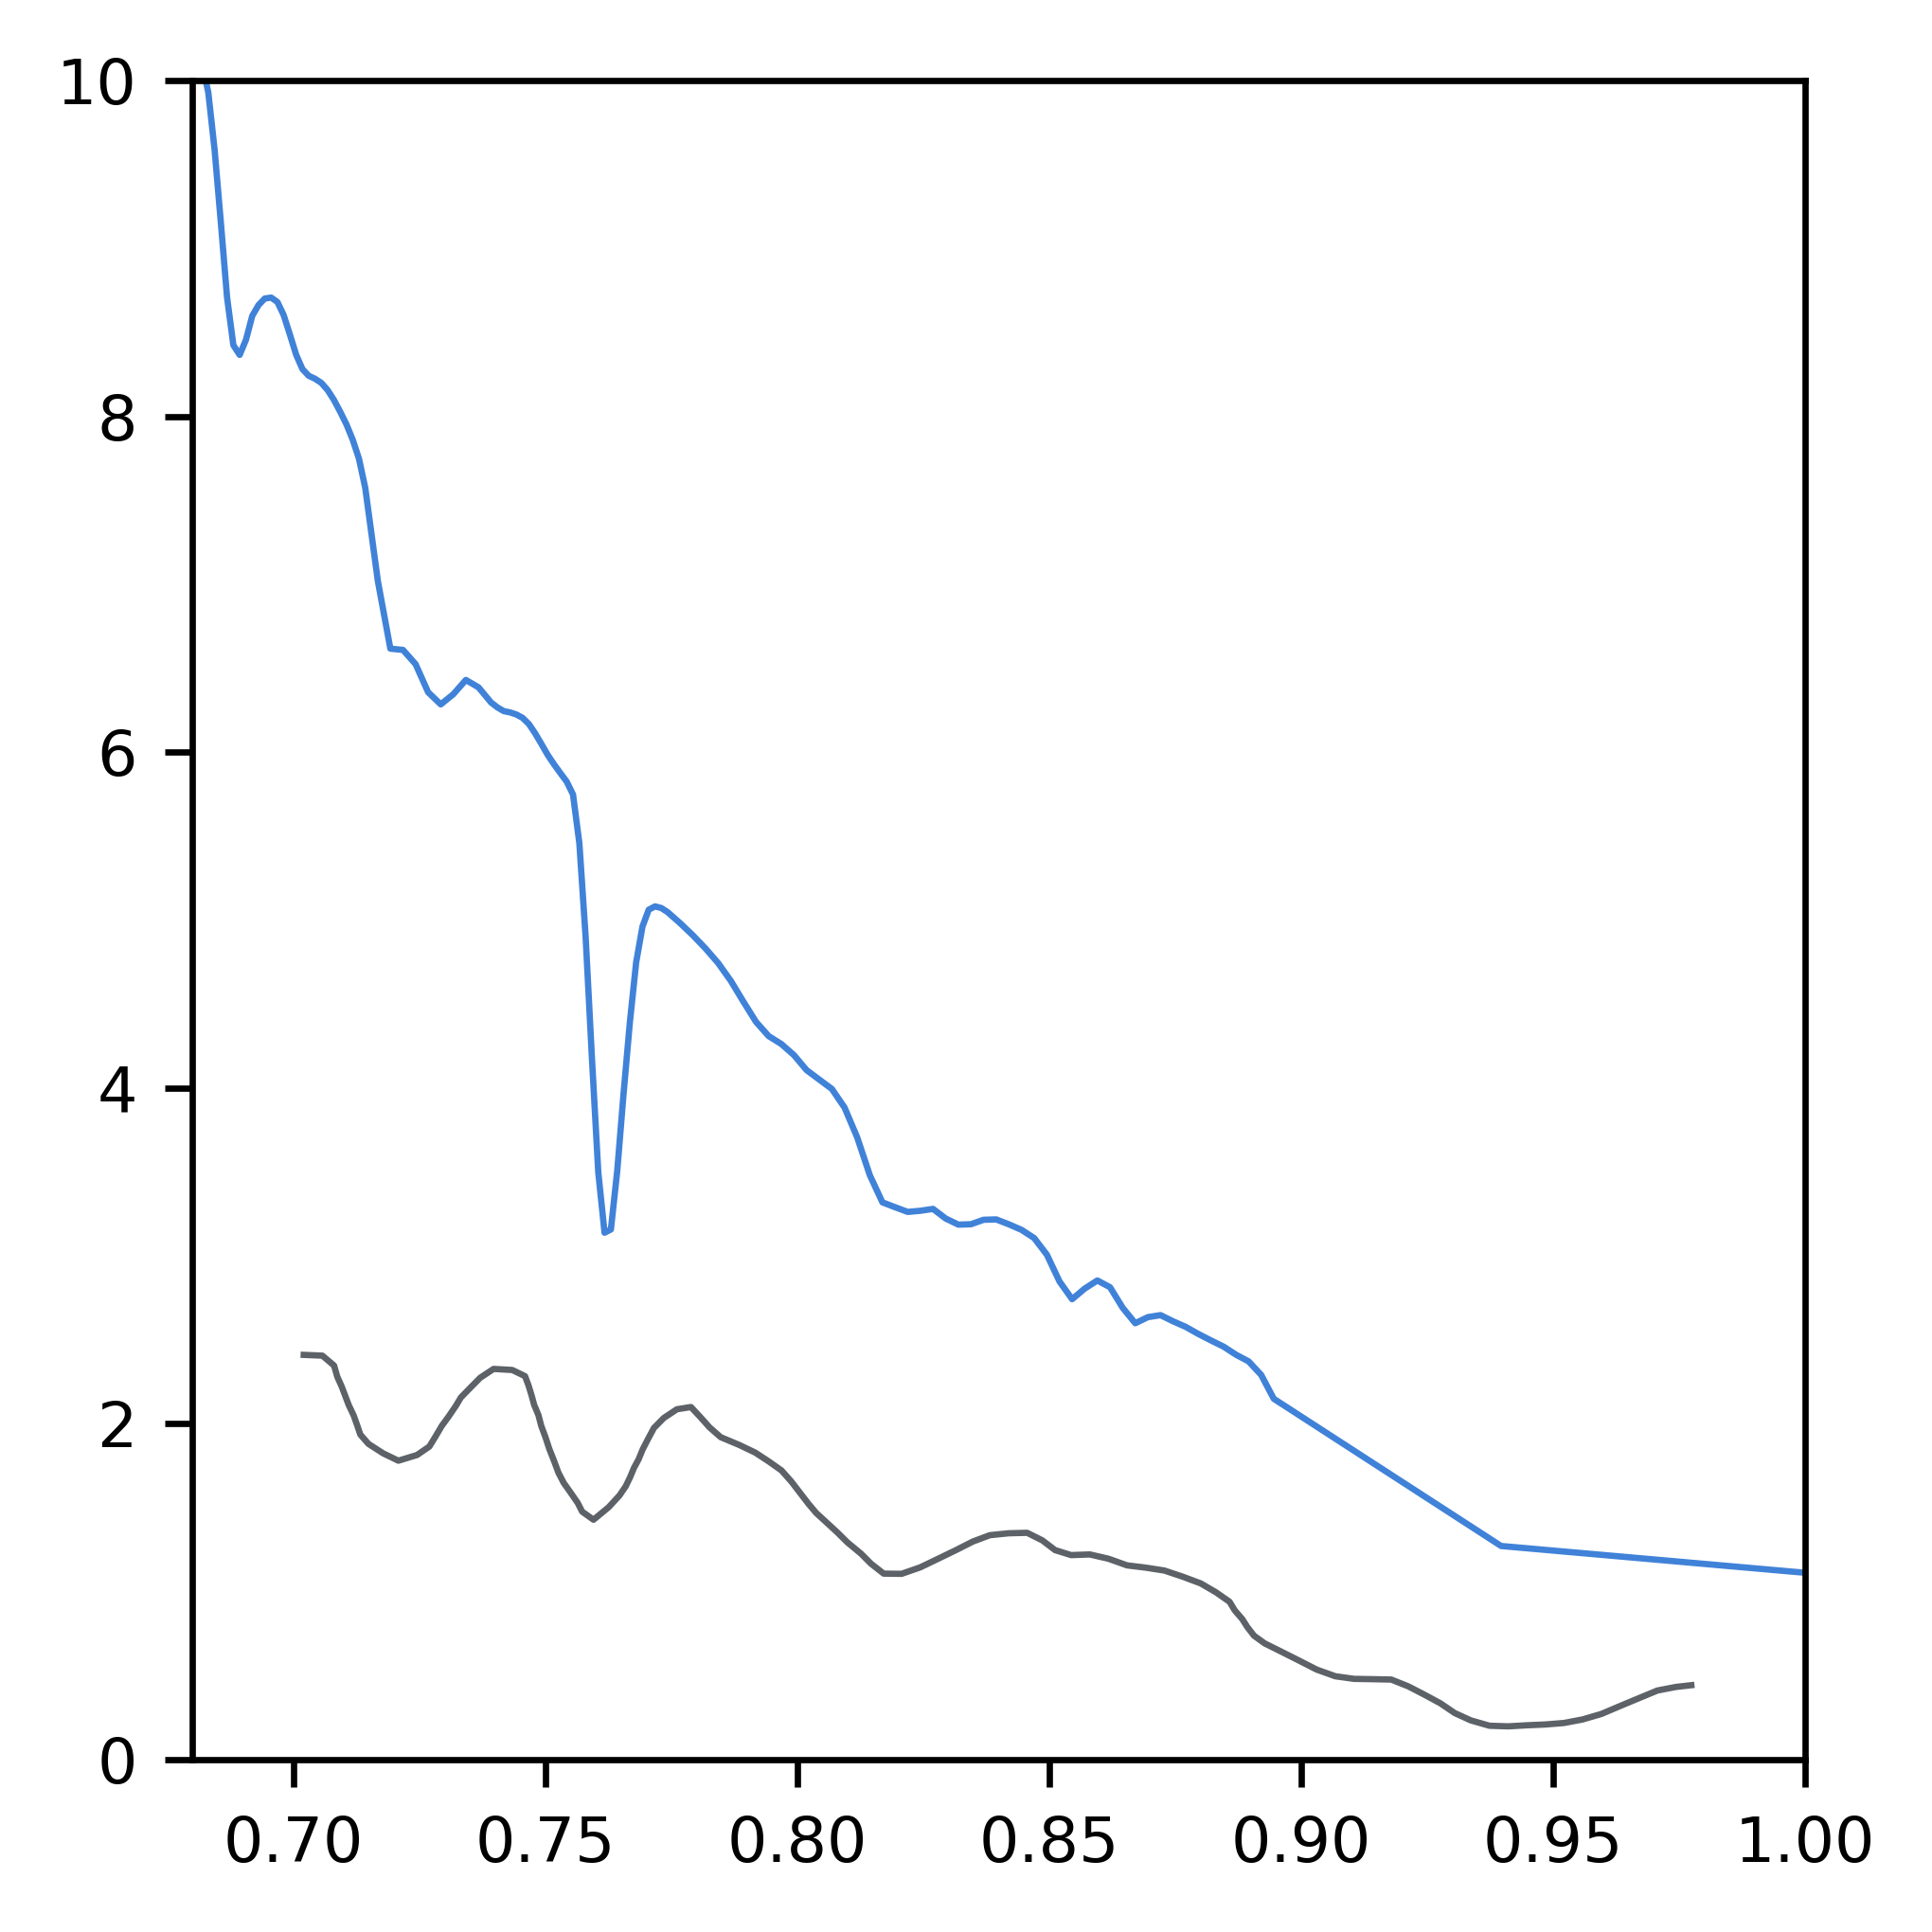

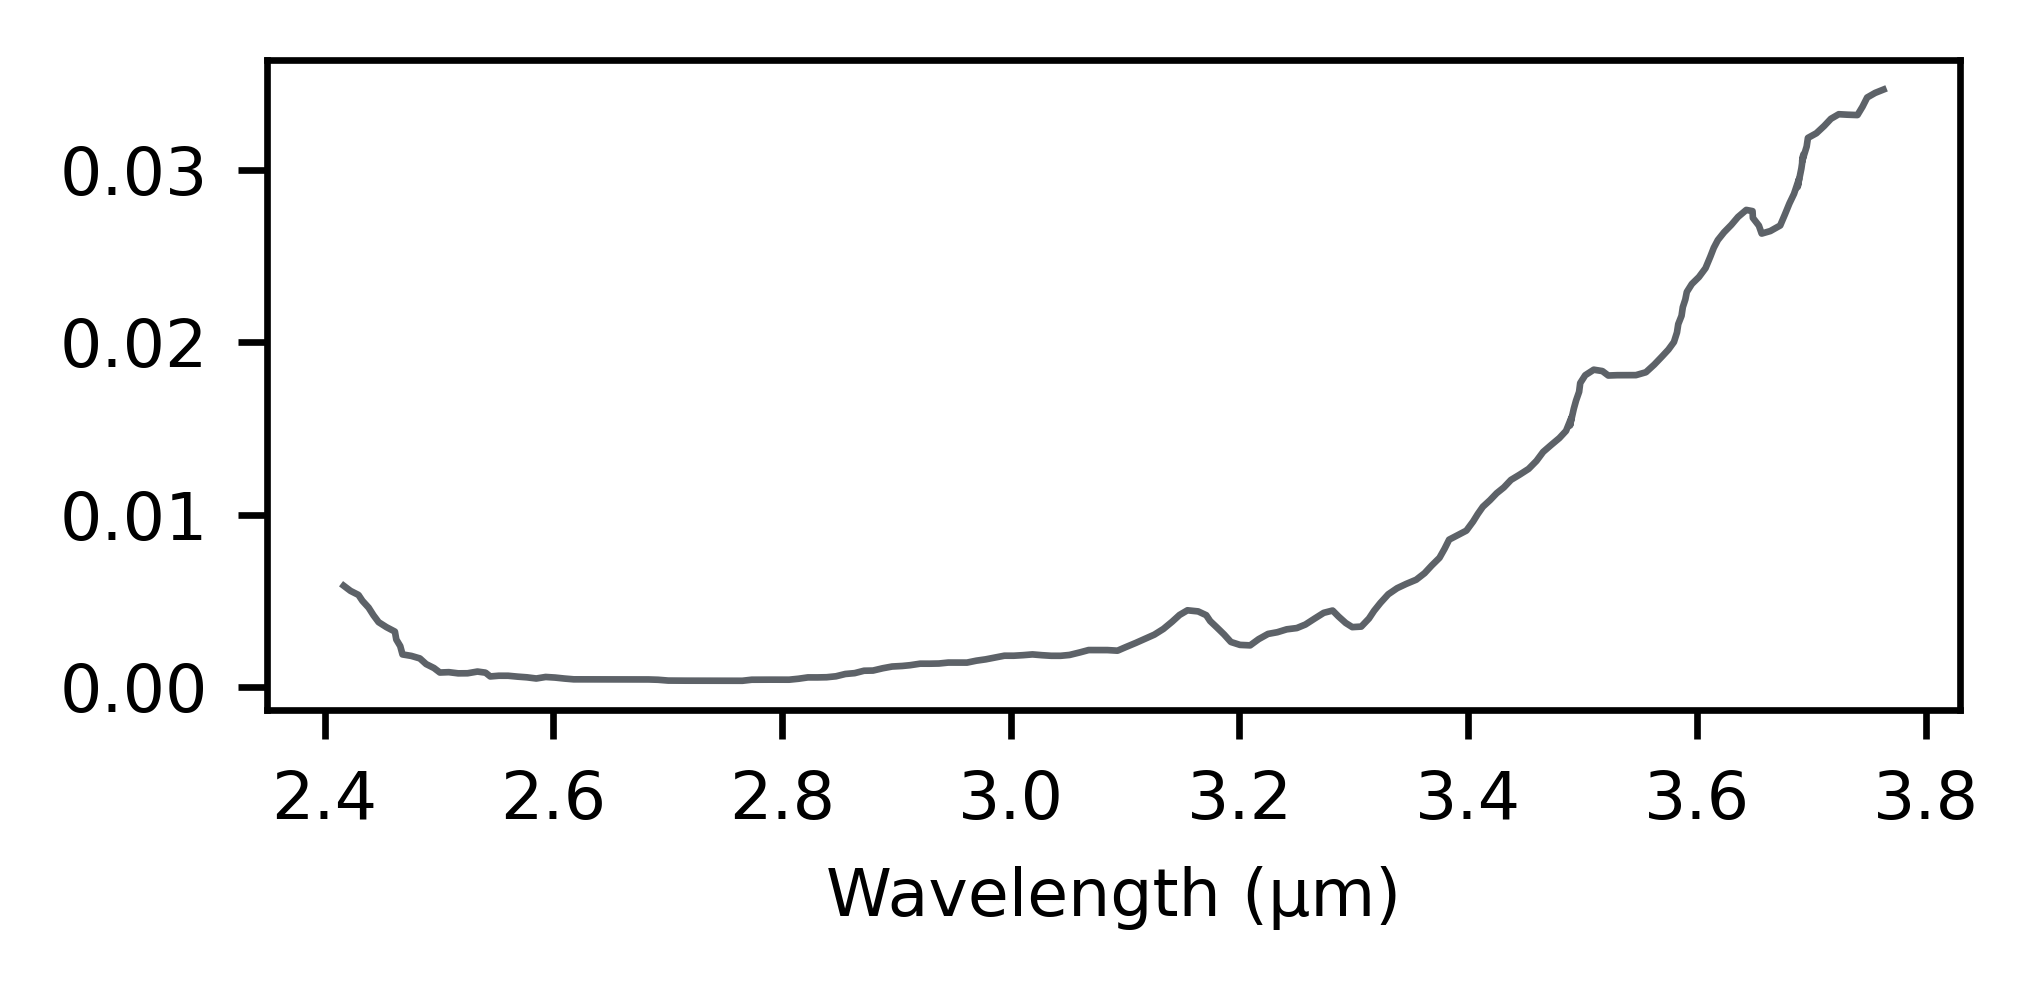

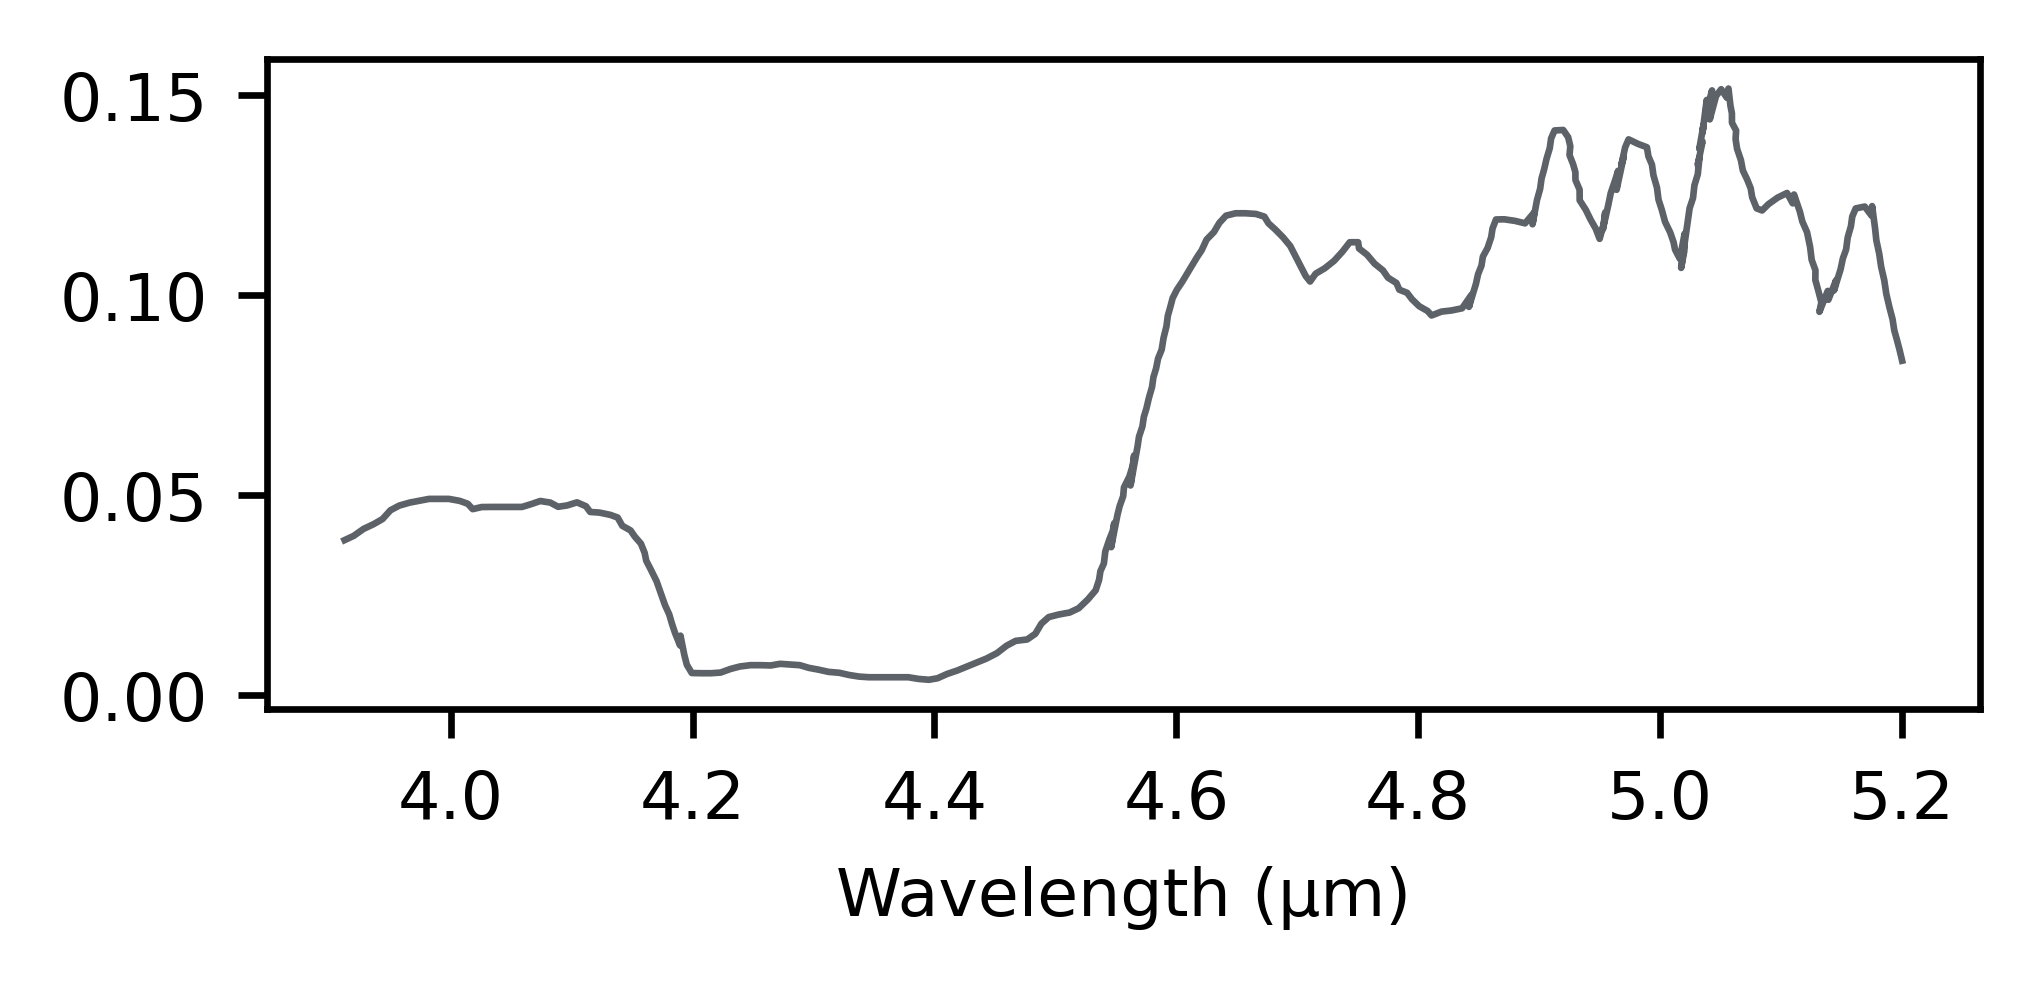

In [10]:
plot_radiance_comparison(galileo_dir)

## 3.2 Volume Mixing Ratios
Linear continuum/interpolation method comparable to methods of Sagan *et al.* (1993) </BR>
See *galileo_utils* for calculations

In [11]:
df_sagan_vmr = calculate_vmr(galileo_dir, gases_config)
display(df_sagan_vmr)

Processing...
> Processed O2   | Mean VMR: 2.102e-01 | Spatial Std Dev: 2.355e-03
> Processed H2O  | Mean VMR: 5.806e-03 | Spatial Std Dev: 2.470e-04
> Processed O3   | Mean VMR: 1.656e-06 | Spatial Std Dev: 1.162e-08


,Mean Optical Depth,Mean Abundance (cm-amagat),PACE Derived Mean VMR,PACE Spatial Std Dev
Gas,,,,
O2,0.5746,168224.3486,2.102e-01,2.355e-03
H2O,0.4303,4645.7142,5.806e-03,2.470e-04
O3,0.3913,1.3252,1.656e-06,1.162e-08


## 3.3 Reflectance
PACE OCI (hyperspectral UV-SWIR) vs. Galileo SSI (6 broadband filters) </BR>

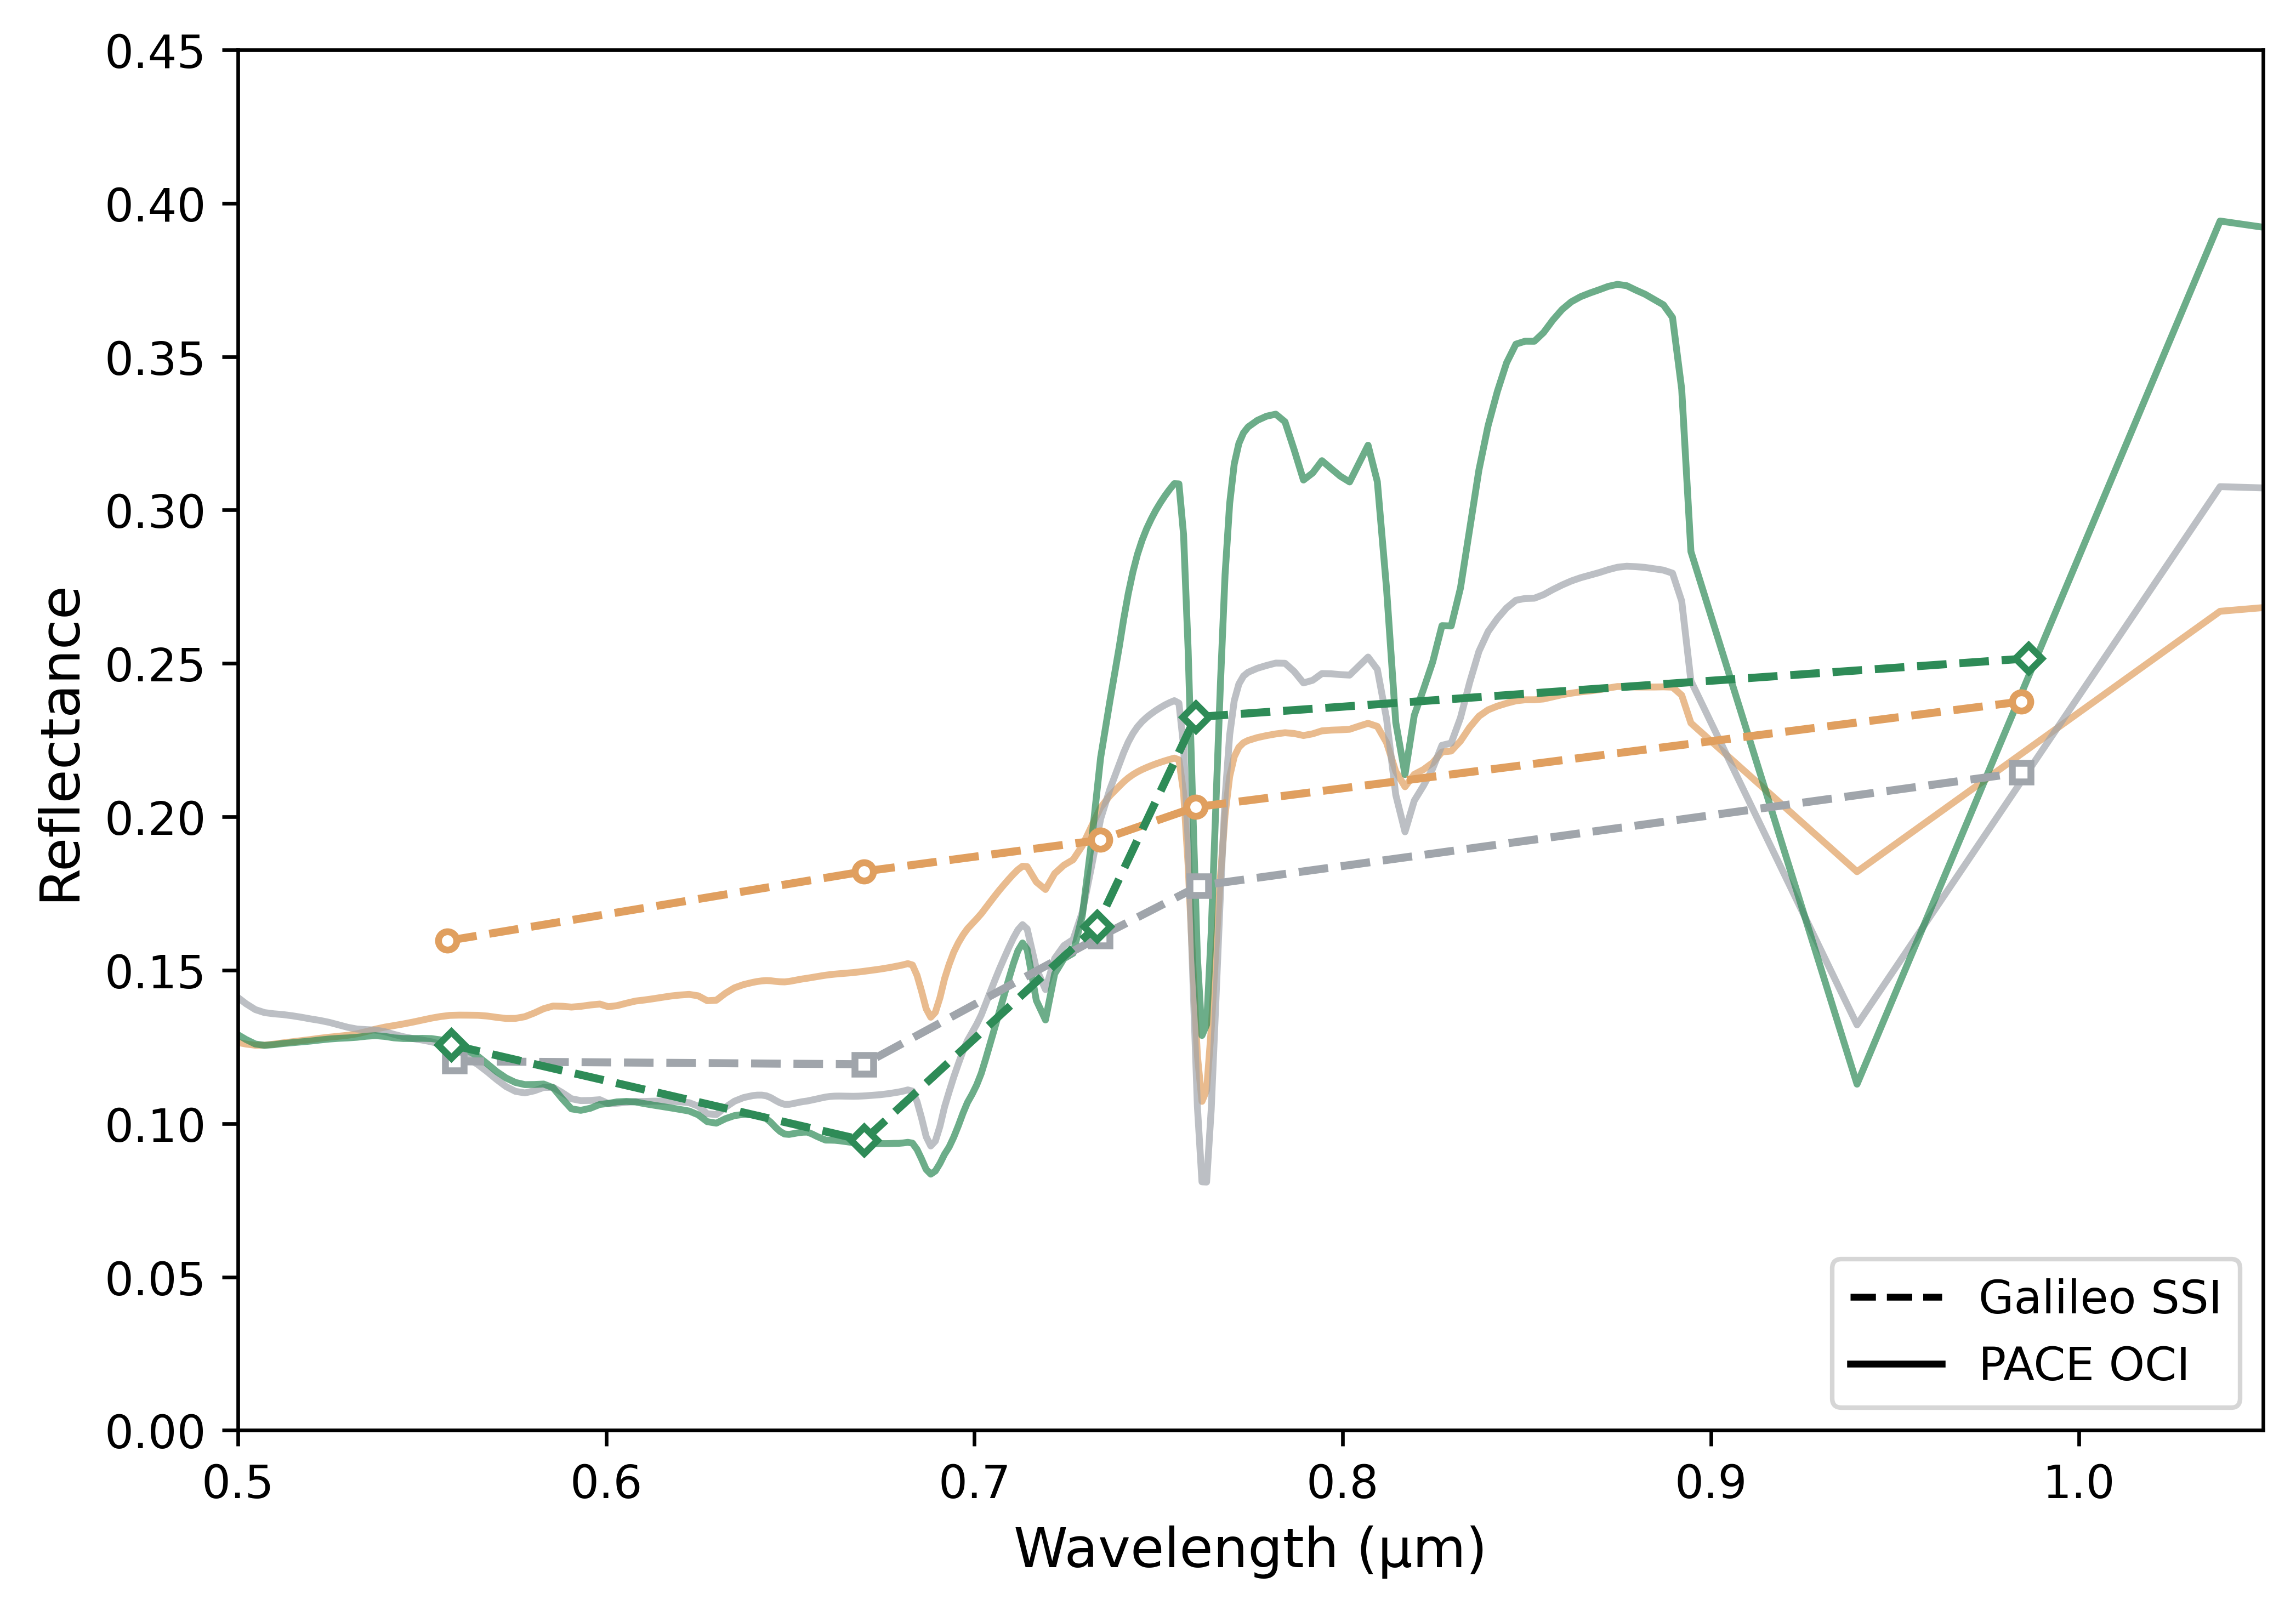

In [12]:
plot_reflectance_comparison(data_dir, correction_factor=1.282)

# 4. GSL Case Study
Using Great Salt Lake (GSL; UT, USA) regions of interest as a case study for examining Earth's biodiversity and biosignature detection. The GSL is a hypersaline lake divided by a gravel-fill railroad, creating two distinct habitats across the North (Region A)/South (B), dominated by microbial communities. Nearby is the the Uinta-Wasatch-Cache National Forest (C), representing our vegetated environment, and the largely abiotic salt flats surround the GSL (D), providing an abiotic control. </BR>
*Modules utilized: pace_utils, biosig_utils, ref_dict* </BR>
## 4.1 Reflectance Spectra
Surface reflectance and TOA reflectance spectra from PACE OCI at the pixel-of-interest (A-D), bounding box region, and whole-granule spatial scales.

In [13]:
# # Convert .pkl cache files -> .csv for downstream analyses (Warning: large file sizes up to 2GB)
# pkl_to_csv(
#     data_dir,
#     "sfrefl_cache/US_west_PACE_OCI.20260604T201346.L2.SFREFL.V3_1.NRT.nc_cache.pkl",
#     os.path.join(data_dir, "US_west_SFREFL2.csv")
# )

# pkl_to_csv(
#     data_dir,
#     "toa_cache/US_west_PACE_OCI.20260604T201346.L1C.V3.5km.nc_cache.pkl",
#     os.path.join(data_dir, "US_west_TOA.csv")
# )

In [14]:
# Read dataframes for biosignature analysis
SFREFL_df = pd.read_csv(os.path.join(data_dir, "US_west_SFREFL.csv"))
TOA_df = pd.read_csv(os.path.join(data_dir, "US_west_TOA.csv"))
dfs = [SFREFL_df, TOA_df]

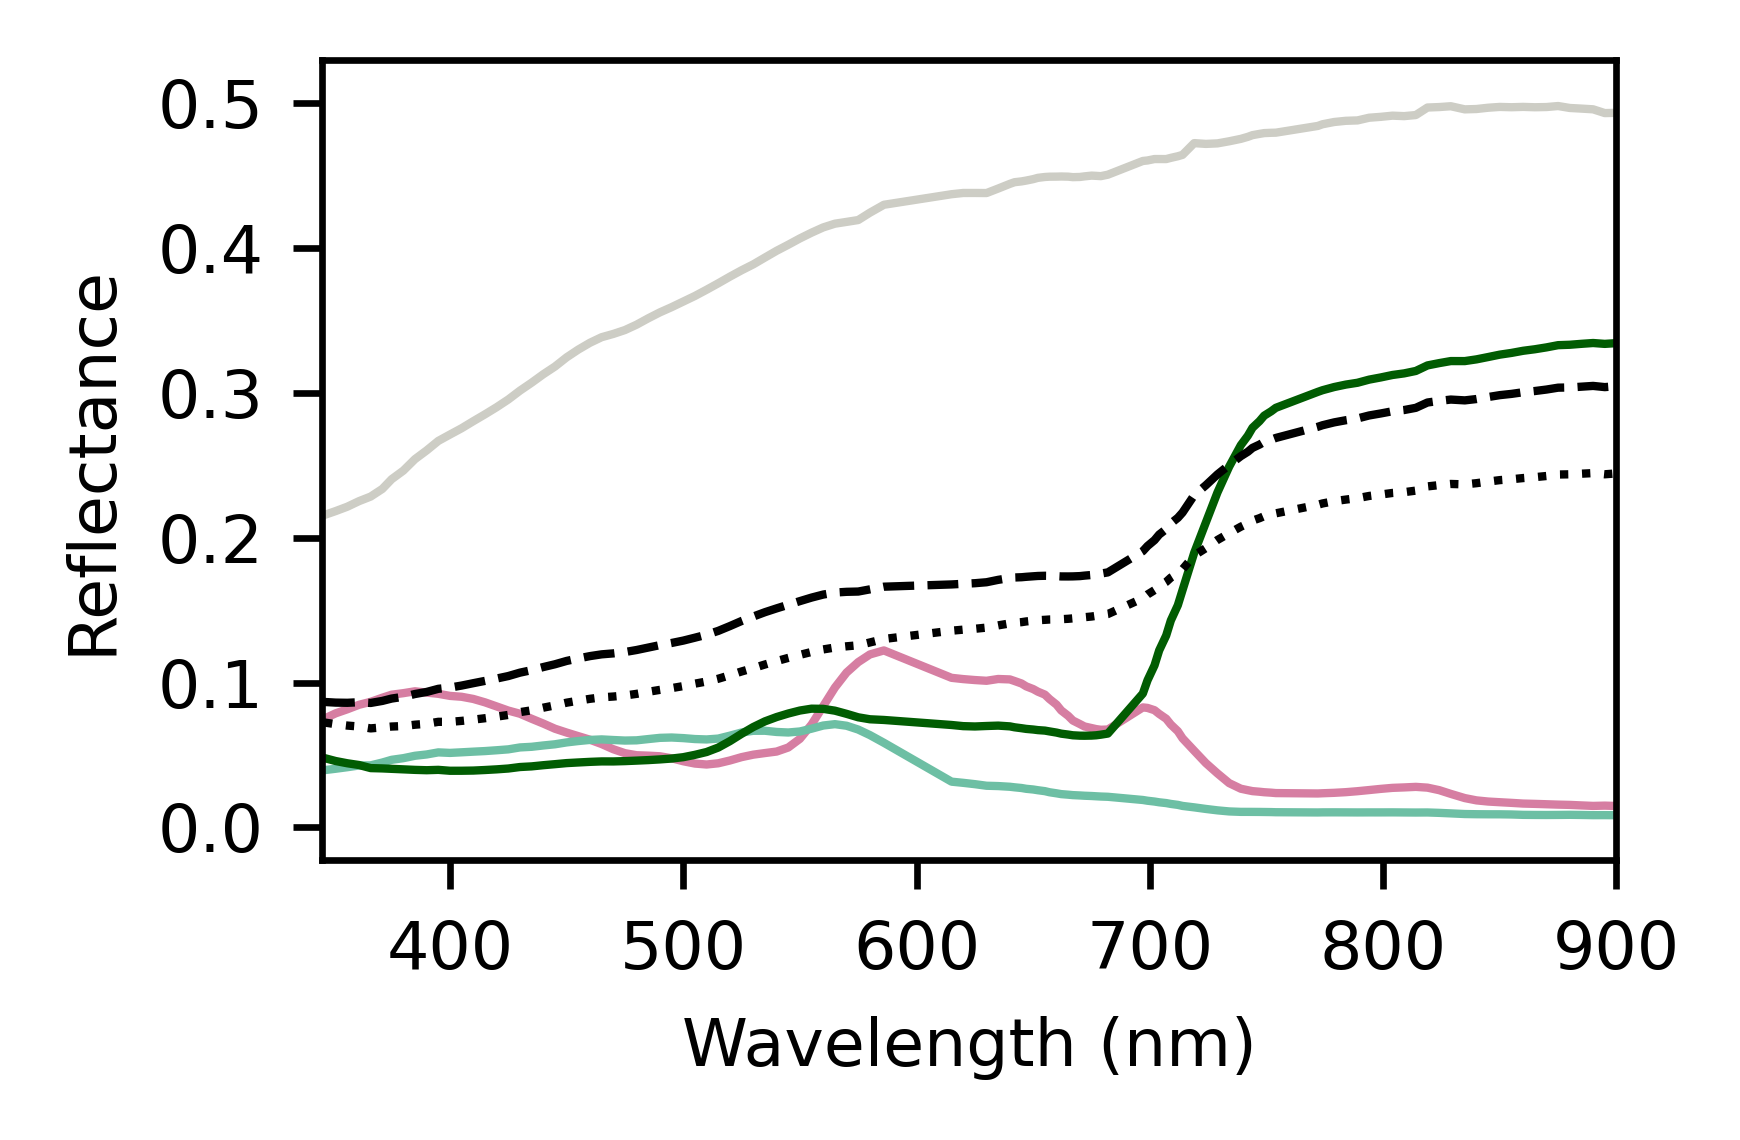

c:\Users\jakel\Desktop\Projects\PACE_pub\notebooks\..\modules\pace_utils.py:1266: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig_leg.tight_layout()


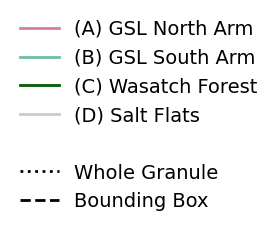

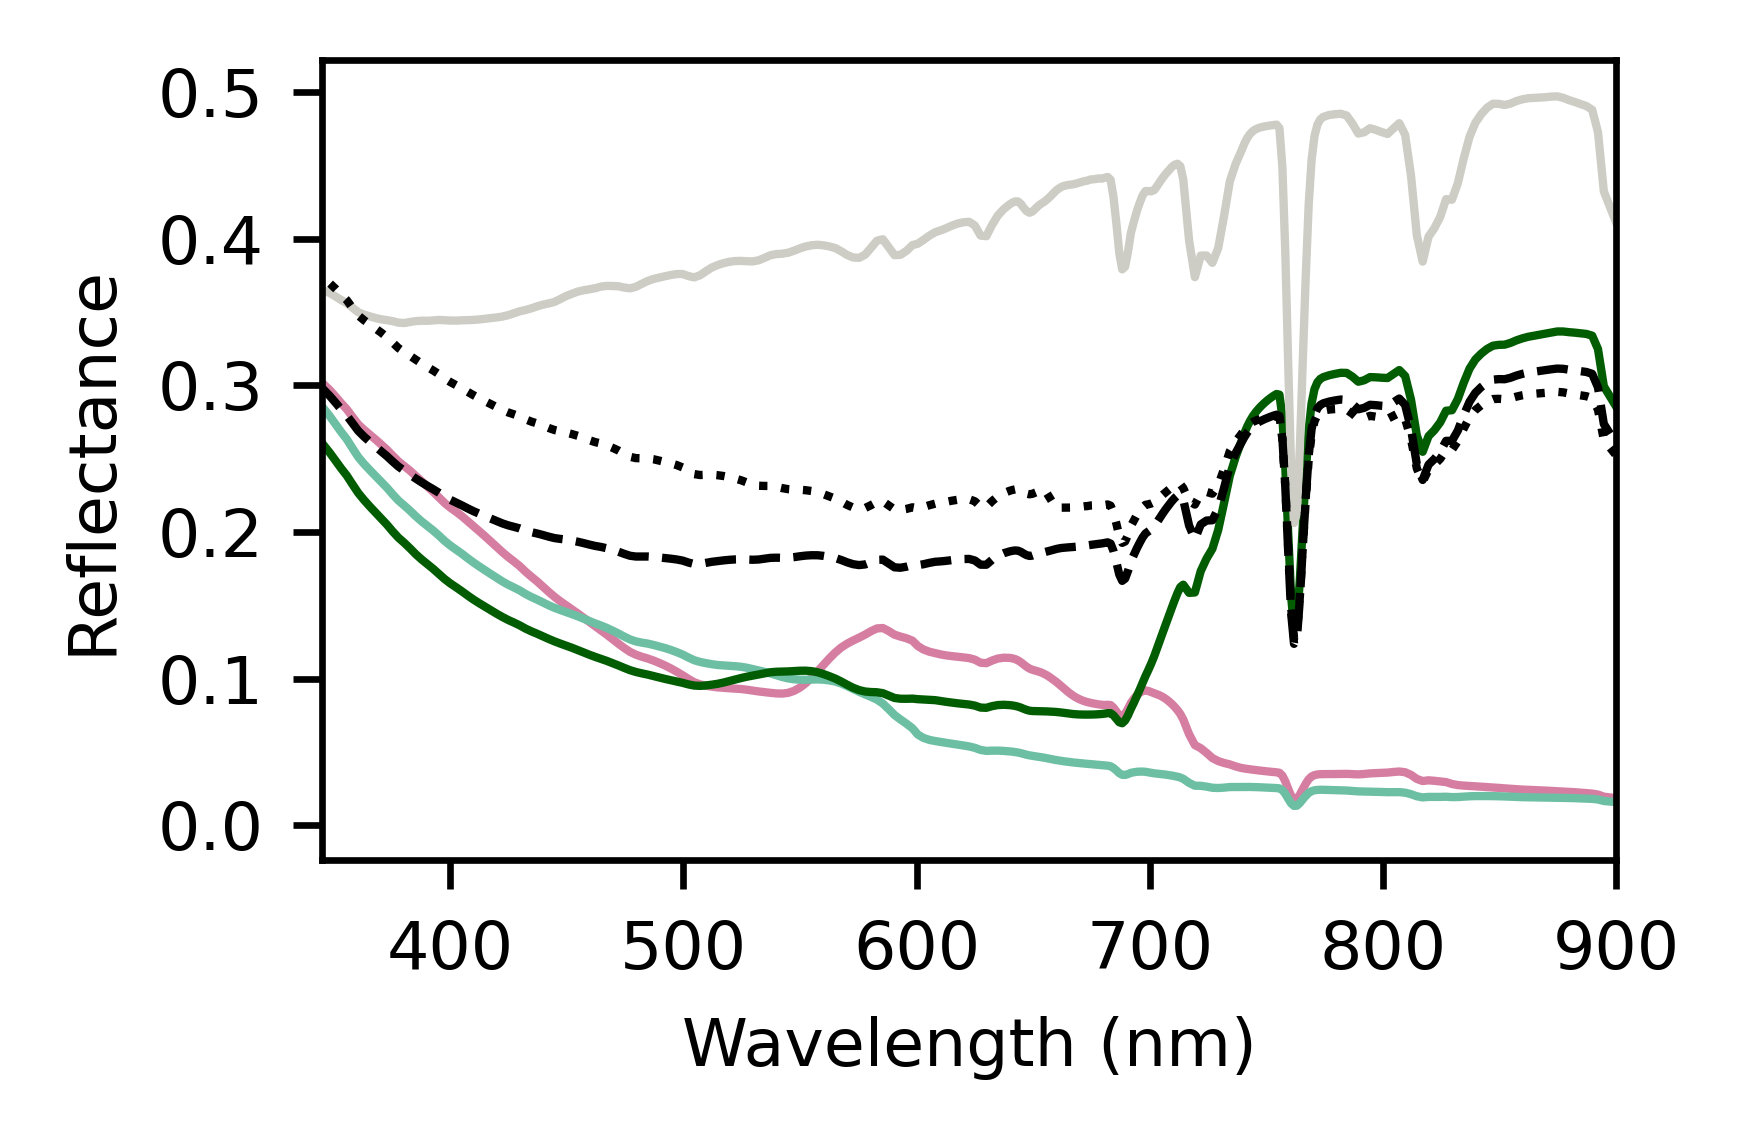

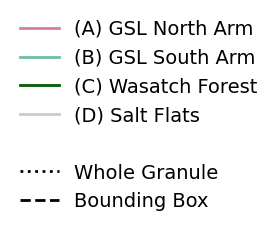

(<Figure size 1800x1200 with 1 Axes>, <Figure size 200x100 with 1 Axes>)

In [15]:
# Plot surface/TOA reflectances for the GSL region (US_west granule)
plot_biomes_csv(dfs[0], GSL_biomes)
plot_biomes_csv(dfs[1],  GSL_biomes)

## 4.2 Biosignature Detection
Pixel-by-pixel linear continuum/interpolation approach (grid search) for detecting biosignature absorption features in PACE OCI TOA reflectance spectra. Resolving power (R; 60-200) is varied through the addition of Gaussian spectral blurring, while signal-to-noise ratio (SNR; 5-30) is varied through the addition of Gaussian noise. For each region, the fraction of pixels in which a biosignature is detectable is calculated across the R-SNR grid. When a biosignature is detectable in >= 50% of the pixels, the SNR required for 50% detection (SNR50) is determined at each R, and the mean+-std of SNR50 across R is calculated.

In [16]:
# Biosignature detection function (~8 min runtime)
from modules.biosig_utils import *
detection = run_detection_grid(dfs[1], GSL_biomes[:5], bands_config)

Processing (A) GSL North Arm: 12 measurements...
Processing (B) GSL South Arm: 15 measurements...
Processing (C) Wasatch Forest: 17 measurements...
Processing (D) Salt Flats: 18 measurements...
Processing Bounding Box: 1091 measurements...

Grid search completed in 335.9 seconds.



Grid Search Sanity Check (Min / Max Fractions)

(A) GSL North Arm:
  -> O2-A               min/max: 0.3333 / 1.0000
  -> H2Ob               min/max: 0.0000 / 0.6667
  -> Bacterioruberin    min/max: 0.0000 / 1.0000
  -> Phycocyanin        min/max: 0.0000 / 0.0000
  -> β-carotene         min/max: 0.0000 / 0.7500
  -> Chlorophyll A      min/max: 0.0000 / 0.0000
  -> VRE                min/max: 0.0000 / 0.0000

(B) GSL South Arm:
  -> O2-A               min/max: 0.2000 / 1.0000
  -> H2Ob               min/max: 0.0000 / 0.8667
  -> Bacterioruberin    min/max: 0.0000 / 0.0000
  -> Phycocyanin        min/max: 0.0000 / 1.0000
  -> β-carotene         min/max: 0.0000 / 0.2000
  -> Chlorophyll A      min/max: 0.0000 / 0.0000
  -> VRE                min/max: 0.0000 / 0.0000

(C) Wasatch Forest:
  -> O2-A               min/max: 0.4118 / 1.0000
  -> H2Ob               min/max: 0.0000 / 1.0000
  -> Bacterioruberin    min/max: 0.0000 / 0.0000
  -> Phycocyanin        min/max: 0.0000 / 0.0000
  -> β-ca

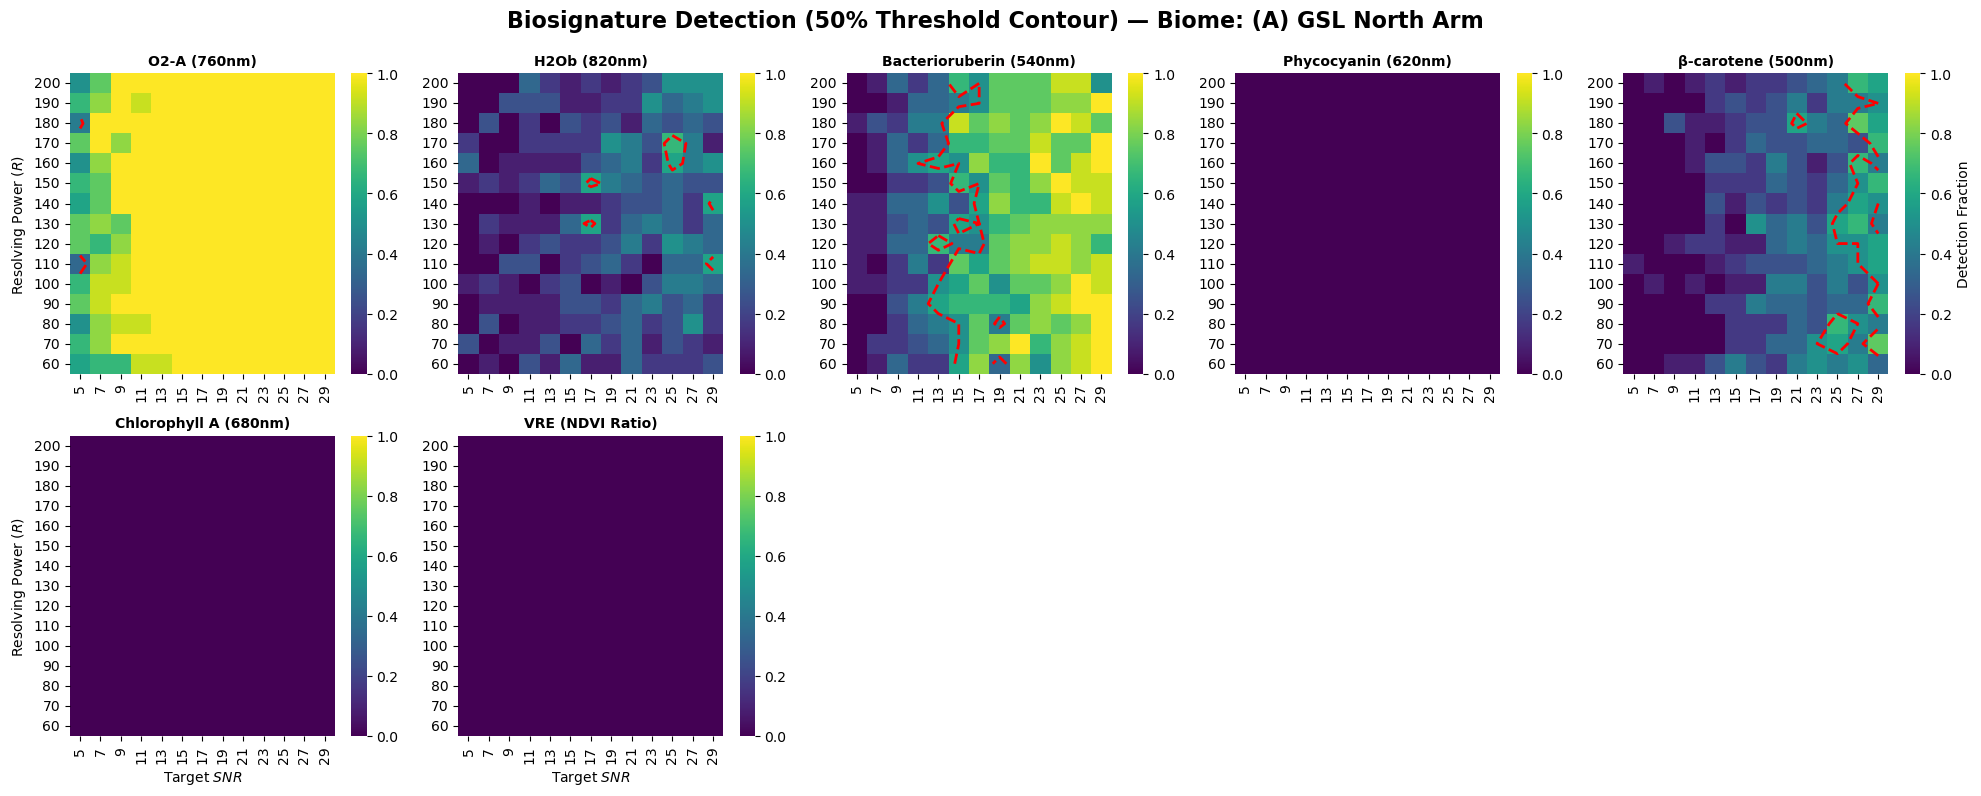

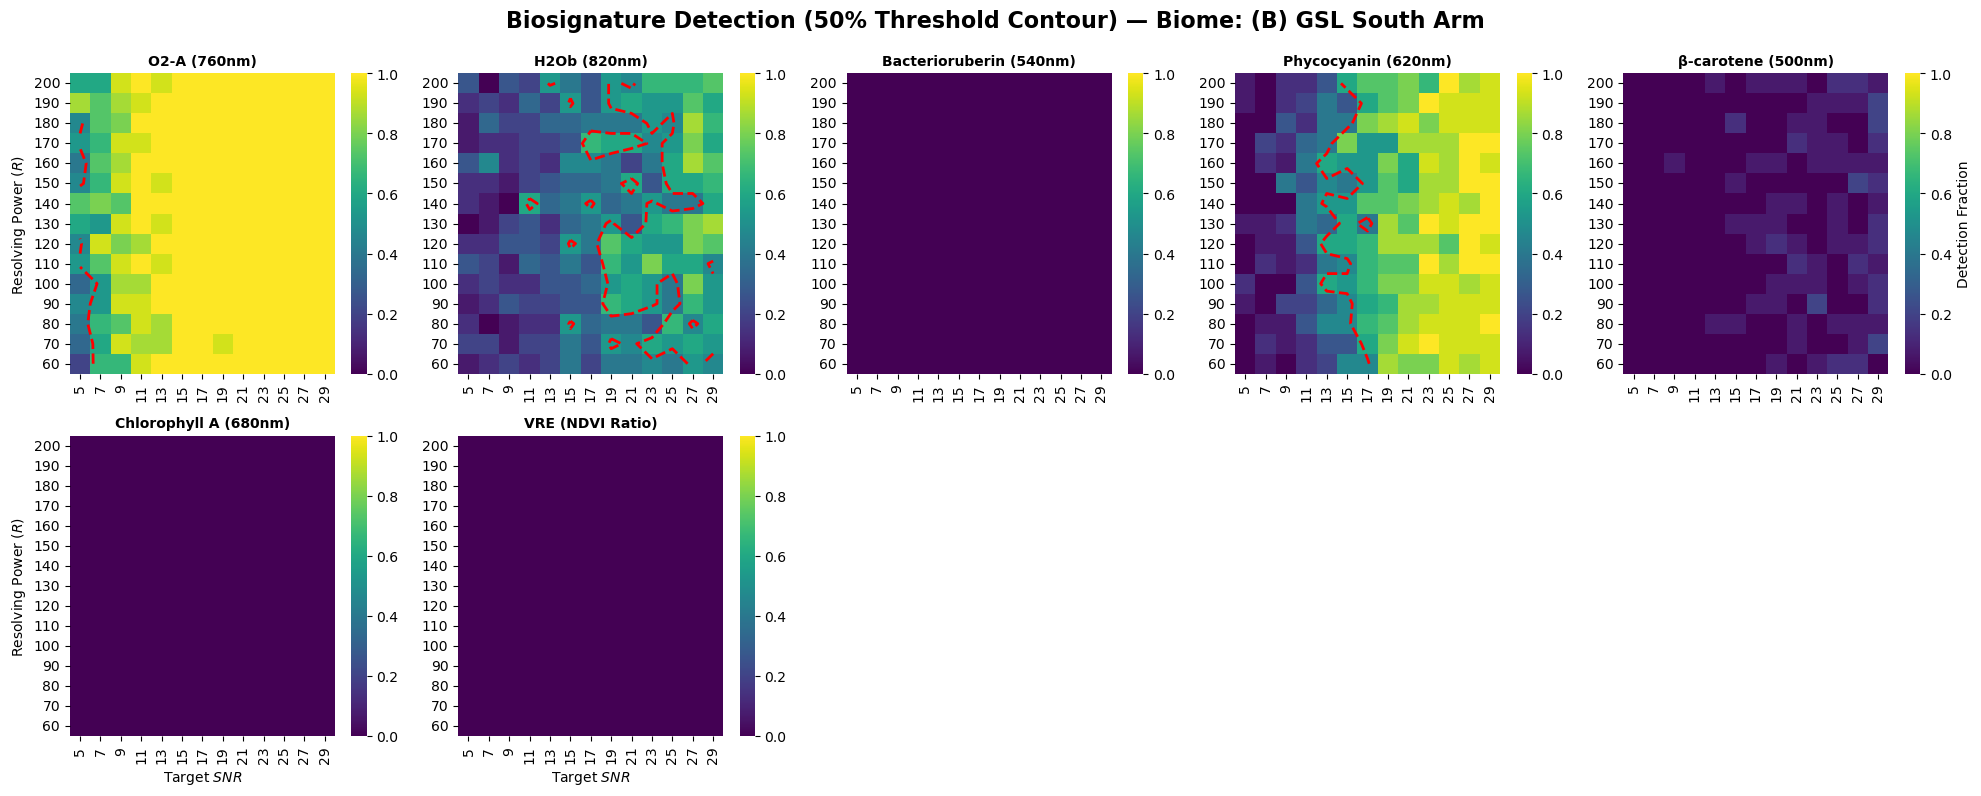

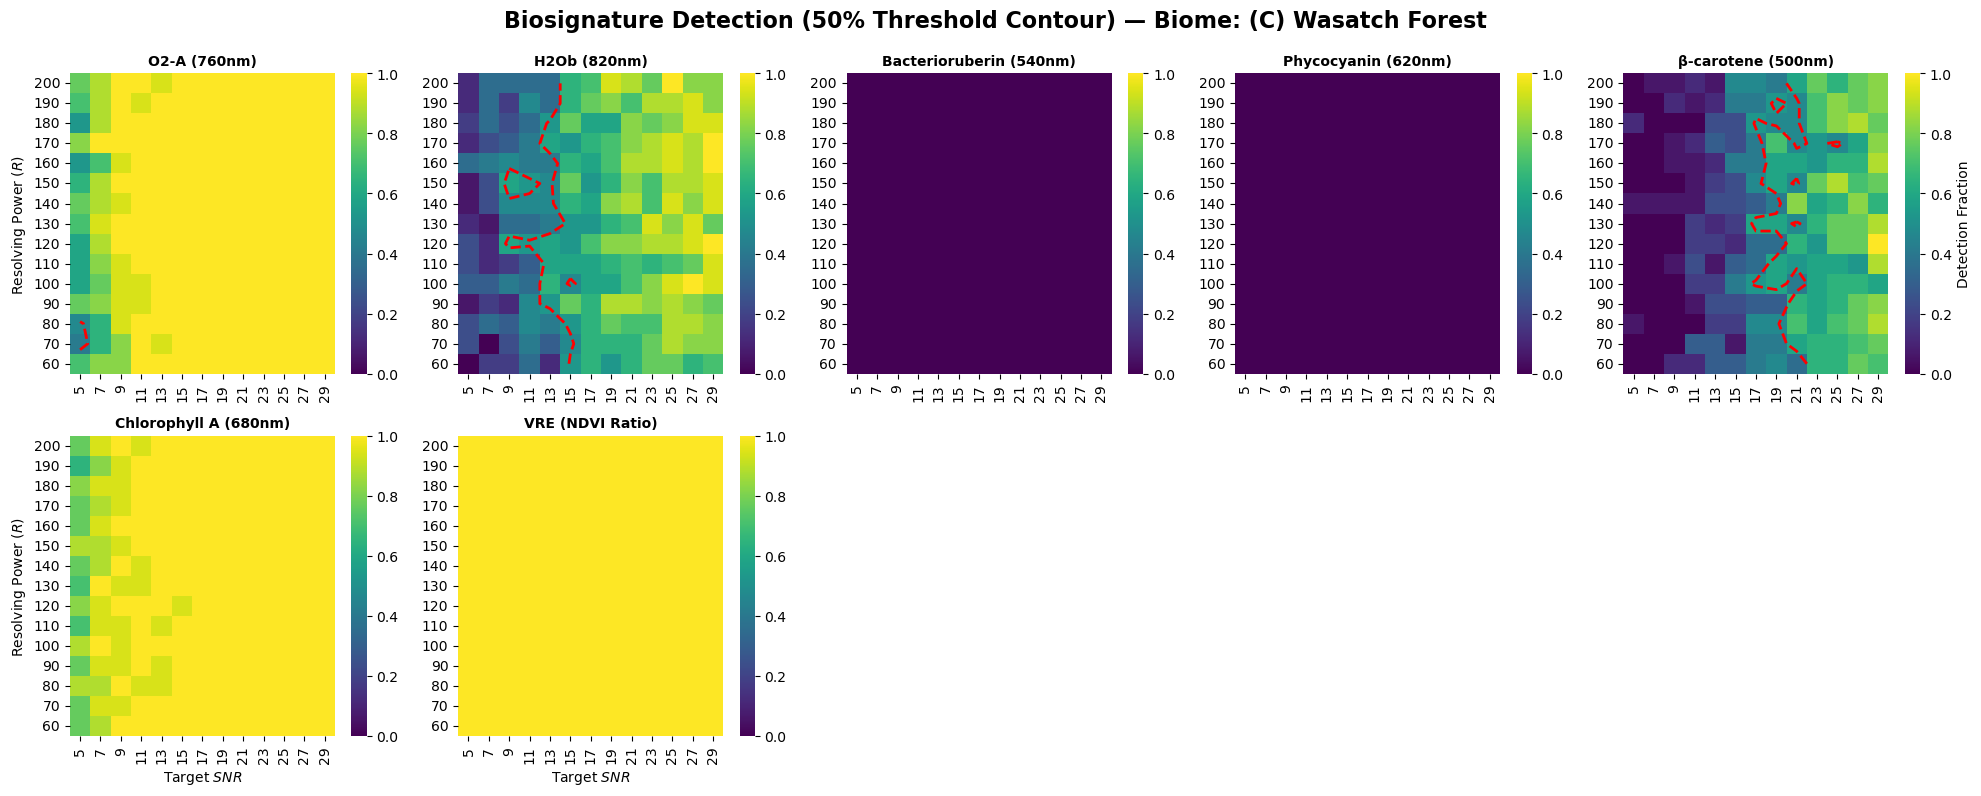

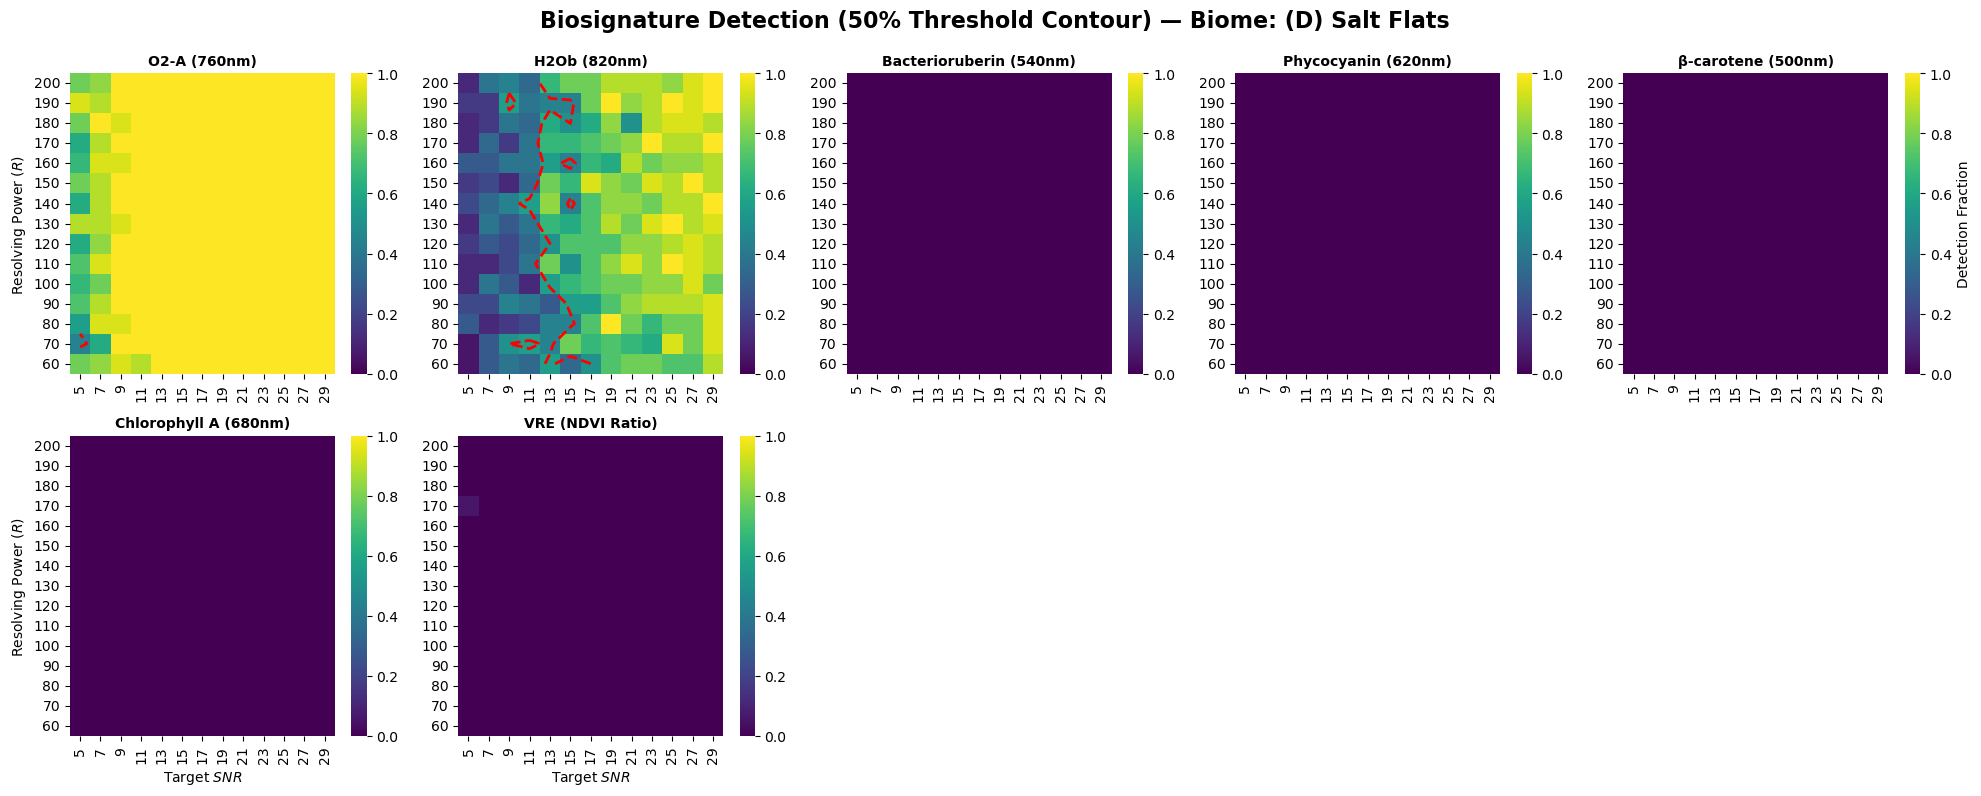

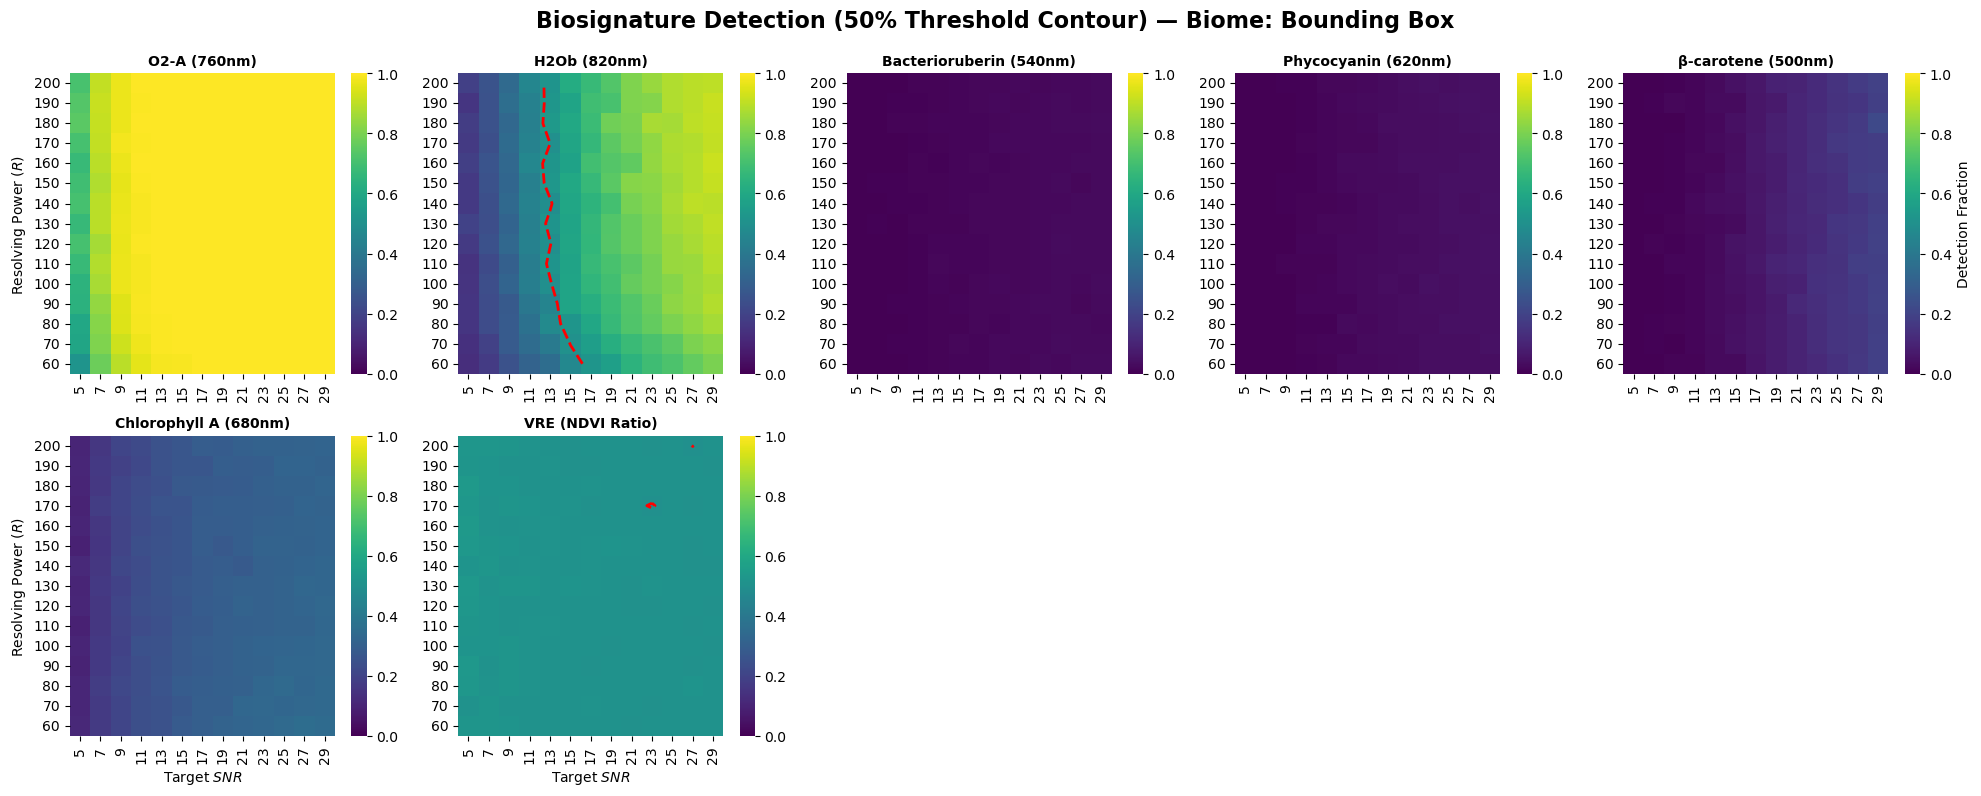

In [17]:
# Print/plot from grid search
print_detection_sanity_check(detection)

plot_detection_heatmaps(
    detection,
    np.arange(5, 31, 2),
    np.arange(60, 201, 10),
    bands_config
)


(A) GSL North Arm
O2-A               SNR50 = 5.00 (range 5.00–5.67, σ=0.18)
H2Ob               SNR50 = 25.00 (range 23.00–28.60, σ=2.20)
Bacterioruberin    SNR50 = 14.00 (range 11.00–17.00, σ=1.42)
Phycocyanin        SNR50 = nan (range nan–nan, σ=nan)
β-carotene         SNR50 = 27.00 (range 20.50–29.00, σ=2.50)
Chlorophyll A      SNR50 = nan (range nan–nan, σ=nan)
VRE                SNR50 = nan (range nan–nan, σ=nan)

(B) GSL South Arm
O2-A               SNR50 = 5.25 (range 5.00–6.67, σ=0.55)
H2Ob               SNR50 = 18.17 (range 10.67–24.00, σ=3.61)
Bacterioruberin    SNR50 = nan (range nan–nan, σ=nan)
Phycocyanin        SNR50 = 15.33 (range 12.00–17.17, σ=1.66)
β-carotene         SNR50 = nan (range nan–nan, σ=nan)
Chlorophyll A      SNR50 = nan (range nan–nan, σ=nan)
VRE                SNR50 = nan (range nan–nan, σ=nan)

(C) Wasatch Forest
O2-A               SNR50 = 5.00 (range 5.00–5.75, σ=0.20)
H2Ob               SNR50 = 13.33 (range 8.50–15.33, σ=1.97)
Bacterioruberin    SNR50 

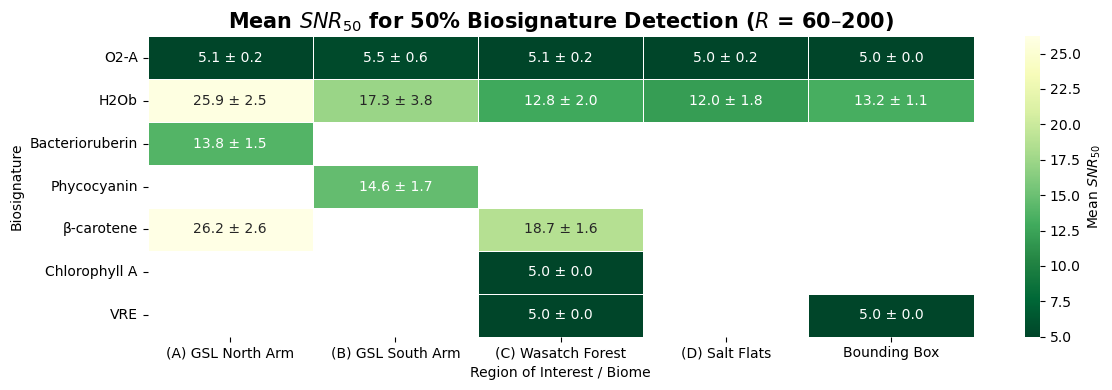

In [18]:
# SNR50 analysis (print/plot)
snr50_by_R, snr50_df, snr50_mean_df, snr50_std_df = calculate_snr50(
    detection, np.arange(5, 31, 2), np.arange(60, 201, 10)
)

print_snr50_stats(snr50_by_R)
plot_snr50_heatmap(snr50_mean_df, snr50_std_df)